# Coffin cavity (4Q): HFSS analysis

4-transmon coffin cavity with a shared readout cavity, 2 readout ports and 4 drive ports.
Geometry comes from `inventor_coffin_4q.py` (Inventor → `inventor_files/coffin_4Q_hfss.stp`, the RF-only export with screw / flange holes suppressed, + `coffin_4Q_params.json`).

Flow (same as `SNAIL_coffin_cavity.ipynb`): import STEP → bounding box − metal = vacuum → SMA pins + matched 50 Ω port faces → cryo-Cu walls → solve.

| Section | Design | Status |
|---|---|---|
| Eigenmode: Cavity | `EM_Cavity` | ready |
| Eigenmode: Cavity + Transmons | `EM_Cavity_with_Transmons` | ready |
| Eigenmode: drive-port check | `EM_drive_check` | qubit T1 limit from the drive ports vs drive-pin height |
| Driven Modal: single port | `DM_1port_Q<n>` | new: one junction port (highest-f qubit), 3 junctions as Lj → BBQ |
| Driven Modal: all ports | `DM` | ready (4×4 junction Y matrix → BBQ) |

Project `$` variables are shared by all designs, so every section builds from the same parameters.

# Setup

## Imports

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from psutil import cpu_count
from scipy.constants import c, giga
from pyaedt import Hfss

In [2]:
%matplotlib inline

In [3]:
"""def f_mnl(a, b, d, mode):
    m, n, l = mode
    return c * np.sqrt((m / a) ** 2 + (n / b) ** 2 + (l / d) ** 2) / 2


def f_n(L, n):
    return (2 * n + 1) * c / (4 * L)


# find a and d that realize mode 1 frequency o Hz
b = parameters["cavity_y"] * milli
x = np.linspace(1, 100, int(1e6)) * milli
idx = np.argmin(np.abs (50, 1) - 100 * giga))
a = d = parameters["cavity_x"] * milli

print(a,d)

eigenmodes, f_sim, _, _ = (
    pd.read_csv("data/eigenmode/cavity_eigenmode_results.csv").to_numpy().T
)

fm = []
TE_cutoff = f_mnl(a, b, d, [1, 0, 1])
fm.append((TE_cutoff, [1, 0, 1]))

for m in range(0, 10):
    for n in range(0, 10):
        for l in range(0, 10):
            mode = [m, n, l]
            frequency = f_mnl(a, b, d, mode)
            if mode != [0, 0, l] and mode != [m, 0, 0]:
                if frequency > TE_cutoff:
                    fm.append((frequency, mode))

modes = np.array([sorted(fm)[i][1] for i in range(20)])[: len(f_sim)]
f_anal = np.array([sorted(fm)[i][0] for i in range(20)])[: len(f_sim)]

# append sma port modes
# there are two ports with the same pin lengths
sma_modes = np.array([f_n(sma_pin_length * 1e-3, 0), f_n(sma_pin_length * 1e-3, 0)])
f_anal = np.append(f_anal, sma_modes)
f_anal = np.sort(f_anal)[:-2]

fig, ax = plt.subplots()

ax.plot(f_anal / giga, "bs--", label=r"Analytical")
ax.plot(f_sim, "r^", label="Simulation")

ax.set_xticks(range(len(eigenmodes)))
ax.set_xticklabels(eigenmodes)
ax.set_ylabel(r"$\text{Frequency} \; (\mathrm{GHz})$")
ax.legend()
plt.savefig("figures/cavity_modes")
plt.show()"""

'def f_mnl(a, b, d, mode):\n    m, n, l = mode\n    return c * np.sqrt((m / a) ** 2 + (n / b) ** 2 + (l / d) ** 2) / 2\n\n\ndef f_n(L, n):\n    return (2 * n + 1) * c / (4 * L)\n\n\n# find a and d that realize mode 1 frequency o Hz\nb = parameters["cavity_y"] * milli\nx = np.linspace(1, 100, int(1e6)) * milli\nidx = np.argmin(np.abs (50, 1) - 100 * giga))\na = d = parameters["cavity_x"] * milli\n\nprint(a,d)\n\neigenmodes, f_sim, _, _ = (\n    pd.read_csv("data/eigenmode/cavity_eigenmode_results.csv").to_numpy().T\n)\n\nfm = []\nTE_cutoff = f_mnl(a, b, d, [1, 0, 1])\nfm.append((TE_cutoff, [1, 0, 1]))\n\nfor m in range(0, 10):\n    for n in range(0, 10):\n        for l in range(0, 10):\n            mode = [m, n, l]\n            frequency = f_mnl(a, b, d, mode)\n            if mode != [0, 0, l] and mode != [m, 0, 0]:\n                if frequency > TE_cutoff:\n                    fm.append((frequency, mode))\n\nmodes = np.array([sorted(fm)[i][1] for i in range(20)])[: len(f_sim)]\nf_anal

## Paths, parameters and solver settings

In [4]:
NAME   = "coffin_4Q"
BASE   = Path(r"C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q")
STEP   = BASE / "inventor_files" / f"{NAME}_hfss.stp"   # RF-only export: screw / flange holes suppressed
PARAMS = BASE / "inventor_files" / f"{NAME}_params.json"
AEDT   = BASE / "hfss_files" / f"{NAME}.aedt"

for d in ("hfss_files", "data/eigenmode", "data/driven_modal", "data/bbq", "figures"):
    (BASE / d).mkdir(parents=True, exist_ok=True)

# geometry values (mm) written by the Inventor builder
P = json.loads(PARAMS.read_text())["values"]
READOUTS = [(P["ro1_x"], P["ro1_z"]), (P["ro2_x"], P["ro2_z"])]
QUBIT_X  = [P[f"q{i}_x"] for i in range(1, 5)]
# drive bores: per-qubit distance from the cavity wall (outer Q1/Q4 and inner Q2/Q3 differ)
DRIVE_DY_KEY = {1: "drive_dy_outer", 2: "drive_dy_inner", 3: "drive_dy_inner", 4: "drive_dy_outer"}
assert all(k in P for k in DRIVE_DY_KEY.values()), \
    f"{PARAMS.name} has no drive_dy_outer / drive_dy_inner: rerun inventor_coffin_4q.py, then rerun this cell"
Y_DRIVES = [-(P["cav_W"] / 2 + P[DRIVE_DY_KEY[i]]) for i in range(1, 5)]   # drive pin / bore y, Q1..Q4

# SMA pins (same 1.27 mm center pin as the SNAIL coffin)
PIN_R         = 1.27 / 2     # mm
RO_PIN_LEN    = 5.0          # mm, readout pin length in from the +y face
DRIVE_PIN_GAP = 2.0          # mm, drive pin tip height above the seam (z = 0). The top clearance pocket
                             # ceiling is at z = top_pocket_D, so a gap below that puts the tip inside the pocket.

# 50 ohm termination of each SMA bore. HFSS impedance boundaries are SURFACE impedances (ohm per square).
# A sheet across a coax annulus (pin radius a, bore radius b) with radial current has R = Zs * ln(b/a) / (2 pi),
# so terminating the line in Z0 needs Zs = 2 pi Z0 / ln(b/a): ~373 ohm/sq here (vs 377 for free space).
# Writing "50" directly gave ~6.7 ohm, a near-short that made the drive pins Q ~ 6 resonators at ~5.5 GHz.
PORT_Z0 = 50.0               # ohm


def coax_sheet_ohms(bore_dia, pin_r=PIN_R, z0=PORT_Z0):
    return 2 * np.pi * z0 / np.log((bore_dia / 2) / pin_r)


ZS_RO, ZS_DRIVE = coax_sheet_ohms(P["ro_dia"]), coax_sheet_ohms(P["drive_dia"])
print(f"[ports] {PORT_Z0:g} ohm terminations: readout {ZS_RO:.1f} ohm/sq, drive {ZS_DRIVE:.1f} ohm/sq "
      f"(coax line impedance {59.96 * np.log(P['ro_dia'] / 2 / PIN_R):.1f} ohm)")

CRYO_CU_SIGMA = 5.8e9        # S/m, OFHC Cu at 4 K, RRR ~100

num_cores = cpu_count(logical=False)
pd.Series(P, name="mm").to_frame().T


[ports] 50 ohm terminations: readout 373.4 ohm/sq, drive 373.4 ohm/sq (coax line impedance 50.5 ohm)


,cav_L,cav_W,cav_H,cav_r,wall_x,wall_z,wall_back,chip_T,tunnel_W,tunnel_L,...,sma_tap_drill,sma_flange_T,drive_flange_dy,drive_flange_dx,hw_min_wall,ovl,block_L,block_H,y_front,y_back
mm,60.0,8.0,20.27,2.0,10.0,5.0,10.0,0.5,3.45,18.63,...,1.778,1.57,4.421632,3.096006,1.0,0.5,80.0,30.27,12.75,32.63


## Initialize HFSS

In [5]:
hfss = Hfss(project=str(AEDT), design="EM_Cavity", solution_type="Eigenmode", remove_lock=True)
hfss.modeler.model_units = "mm"

# cryogenic copper (project-wide material, used by the cryo_copper boundary in every design)
if not hfss.materials.exists_material("cryo_copper"):
    hfss.materials.add_material("cryo_copper")
hfss.materials["cryo_copper"].conductivity = CRYO_CU_SIGMA

PyAEDT INFO: Parsing C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt.
PyAEDT INFO: Python version 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)].
PyAEDT INFO: PyAEDT version 0.24.1.
PyAEDT INFO: Initializing new Desktop session.
PyAEDT INFO: Log on console is enabled.
PyAEDT INFO: Log on file C:\Users\epm114\AppData\Local\Temp\pyaedt_epm114_01d5a30a-cd06-40bc-94f4-808a862f0973.log is enabled.
PyAEDT INFO: Log on AEDT is disabled.
PyAEDT INFO: Found active AEDT gRPC session on port 49815.
PyAEDT INFO: Connecting to AEDT gRPC session on port 49815.
PyAEDT INFO: AEDT installation Path C:\Program Files\AnsysEM\v232\Win64
PyAEDT INFO: Client application successfully started.
PyAEDT INFO: Debug logger is disabled. PyAEDT methods will not be logged.
PyAEDT INFO: File C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt correctly loaded. Elapsed time: 0m 2sec
PyAEDT INFO: Project coffin_4Q set to act

In [6]:
# Inventor parameters -> project ($) variables, shared by every design
for k, v in P.items():
    hfss[f"${k}"] = f"{v}mm"
hfss["$pin_r"]         = f"{PIN_R}mm"
hfss["$ro_pin_len"]    = f"{RO_PIN_LEN}mm"
hfss["$drive_pin_gap"] = f"{DRIVE_PIN_GAP}mm"
hfss["$drive_pin_len"] = "$block_H/2 - $drive_pin_gap"

## Helpers
Shared by every section: geometry build, eigenmode setup/results, analytic box modes, field plots.

In [7]:
def use_design(name, solution_type="Eigenmode"):
    # Create the design if needed, then make it active (same pattern as the SNAIL notebook).
    if name not in hfss.design_list:
        hfss.insert_design(name, solution_type)
    else:
        hfss.set_active_design(name)
    hfss.modeler.model_units = "mm"


def build_cavity(drive_pin_gap=None):
    # STEP import -> vacuum -> SMA pins -> 50 ohm port faces + cryo-Cu walls.
    # drive_pin_gap: drive-pin tip height above the seam (mm). None = the $drive_pin_gap project variable
    # (DRIVE_PIN_GAP); a number = written into the geometry directly. Sweeps rebuild with a number, because
    # changing $drive_pin_gap on an existing design did not move the pins (Nov 18 sweep: 4 identical solutions).
    # Returns {port_name: face_id}.
    for clear in ("DeleteAllBoundaries", "DeleteAllExcitations"):   # clean rerun
        try:
            getattr(hfss.oboundary, clear)()
        except Exception:
            pass
    if hfss.modeler.object_list:
        hfss.modeler.delete()

    hfss.modeler.import_3d_cad(str(STEP))
    metal = list(hfss.modeler.solid_names)
    assert len(metal) == 2, f"expected 2 solids (top/bottom) from the STEP, got {metal}"

    # unit / placement check against the Inventor parameters
    bb = hfss.modeler.get_model_bounding_box()
    want = [-P["block_L"] / 2, -P["y_back"], -P["block_H"] / 2,
            P["block_L"] / 2, P["y_front"], P["block_H"] / 2]
    assert np.allclose(bb, want, atol=1e-3), f"bounding box {bb} != expected {want} (units?)"

    # bounding box - metal = vacuum
    metal_vol = sum(float(hfss.modeler.oeditor.GetObjectVolume(m)) for m in metal)
    box_dim = [b - a for a, b in zip(bb[:3], bb[3:])]
    hfss.modeler.create_box(origin=bb[:3], sizes=box_dim, name="cavity", material="vacuum")
    hfss.modeler.subtract("cavity", metal, keep_originals=False)
    try:
        hfss.modeler.ungroup(NAME)
    except Exception:
        pass
    vac = float(hfss.modeler.oeditor.GetObjectVolume("cavity"))
    assert np.isclose(vac, np.prod(box_dim) - metal_vol, rtol=1e-6), "vacuum != box - metal"
    print(f"[geom] vacuum volume {vac:.2f} mm^3")

    # SMA center pins (PEC by subtraction)
    pins = []
    for i in (1, 2):
        pins.append(hfss.modeler.create_cylinder(
            "Y", [f"$ro{i}_x", "$y_front - $ro_pin_len", f"$ro{i}_z"],
            "$pin_r", "$ro_pin_len", name=f"ro_pin_{i}").name)
    if drive_pin_gap is None:
        gap_mm, tip_z, pin_len = float(DRIVE_PIN_GAP), "$block_H/2 - $drive_pin_len", "$drive_pin_len"
    else:
        gap_mm = float(drive_pin_gap)
        tip_z, pin_len = f"{gap_mm}mm", f"{P['block_H'] / 2 - gap_mm}mm"
    for i in range(1, 5):
        pins.append(hfss.modeler.create_cylinder(
            "Z", [f"$q{i}_x", f"-($cav_W/2 + ${DRIVE_DY_KEY[i]})", tip_z],
            "$pin_r", pin_len, name=f"drive_pin_{i}").name)
    hfss.modeler.subtract("cavity", pins, keep_originals=False)
    # the pin tip must be a face of the vacuum at z = gap_mm, or the pin is not where we think it is
    for i in range(1, 5):
        if not hfss.modeler.get_faceid_from_position([QUBIT_X[i - 1], Y_DRIVES[i - 1], gap_mm], assignment="cavity"):
            raise RuntimeError(f"drive pin {i}: no tip face at z = {gap_mm} mm above the seam")
    print(f"[geom] drive pin tips at z = {gap_mm} mm (pocket ceiling at {P['top_pocket_D']} mm)")

    # matched PORT_Z0 termination on each bore mouth (point midway between pin and bore wall)
    def face_at(pos):
        fid = hfss.modeler.get_faceid_from_position(pos, assignment="cavity")
        if not fid:
            raise RuntimeError(f"no cavity face at {pos}")
        return fid

    ports = {}
    r_ro = (PIN_R + P["ro_dia"] / 2) / 2
    r_dr = (PIN_R + P["drive_dia"] / 2) / 2
    for i, (x, z) in enumerate(READOUTS, start=1):
        ports[f"ro{i}"] = face_at([x + r_ro, P["y_front"], z])
    for i, x in enumerate(QUBIT_X, start=1):
        ports[f"drive{i}"] = face_at([x + r_dr, Y_DRIVES[i - 1], P["block_H"] / 2])

    omodule = hfss.odesign.GetModule("BoundarySetup")
    for name, fid in ports.items():
        zs = ZS_RO if name.startswith("ro") else ZS_DRIVE          # ohm/sq for a PORT_Z0 line
        omodule.AssignImpedance(["NAME:" + name, "Faces:=", [fid],
                                 "Resistance:=", f"{zs:.4f}", "Reactance:=", "0",
                                 "InfGroundPlane:=", False])
    walls = [f.id for f in hfss.modeler["cavity"].faces if f.id not in ports.values()]
    omodule.AssignFiniteCond(["NAME:cryo_copper", "Faces:=", walls,
                              "UseMaterial:=", True, "Material:=", "cryo_copper",
                              "UseThickness:=", False, "Roughness:=", "0um",
                              "InfGroundPlane:=", False, "IsTwoSided:=", False, "IsInternal:=", True])
    print(f"[bnd] {PORT_Z0:g} ohm ({ZS_RO:.1f} / {ZS_DRIVE:.1f} ohm/sq) on {list(ports)}; "
          f"cryo_copper on {len(walls)} faces")
    hfss.modeler.fit_all()
    return ports


def eigen_setup(name, **props):
    # Create the eigenmode setup, or update an existing one so edits here take effect.
    if name in hfss.get_setups():
        s = hfss.get_setup(name)
        s.props.update(props)
        s.update()
    else:
        s = hfss.create_setup(name=name, **props)
    return s


def eigenmode_results(csv_name):
    # Frequencies and Q of every solved mode (same extraction as the SNAIL notebook).
    modes = hfss.post.available_report_quantities()
    qs = hfss.post.available_report_quantities(quantities_category="Eigen Q")
    get = lambda expr, f: hfss.post.get_solution_data(expressions=expr).get_expression_data(formula=f)[1][0]
    df = pd.DataFrame({
        "Eigenmode": modes,
        "Frequency_Real (GHz)": [get(m, "real") / giga for m in modes],
        "Frequency_Imag (GHz)": [get(m, "imag") / giga for m in modes],
        "Q": [get(q, "real") for q in qs],
    })
    df.to_csv(BASE / "data/eigenmode" / csv_name, index=False)
    return df


def box_modes(n=30):
    # Analytic modes of the bare cav_L x cav_W x cav_H box. Valid (m,n,l): at most one zero index.
    # 'count' = 2 when all indices are nonzero (TE + TM share the frequency).
    a, b, d = P["cav_L"] * 1e-3, P["cav_W"] * 1e-3, P["cav_H"] * 1e-3
    rows = []
    for m in range(8):
        for n_ in range(8):
            for l in range(8):
                if sum(k == 0 for k in (m, n_, l)) > 1:
                    continue
                f = c / 2 * np.sqrt((m / a) ** 2 + (n_ / b) ** 2 + (l / d) ** 2)
                rows.append((f / giga, f"({m},{n_},{l})", 2 if 0 not in (m, n_, l) else 1))
    rows.sort()
    return pd.DataFrame(rows[:n], columns=["f_box (GHz)", "mode (m,n,l)", "count"])


def match_box_modes(df, rel_tol=0.03, q_min=100):
    # Label each HFSS mode with the nearest bare-box mode; low-Q or far-off modes are flagged.
    box = box_modes()
    out = df.copy()
    labels, f_box, dev = [], [], []
    for f, q in zip(df["Frequency_Real (GHz)"], df["Q"]):
        k = (box["f_box (GHz)"] - f).abs().idxmin()
        fb = box.loc[k, "f_box (GHz)"]
        if q < q_min:
            labels.append("pin/port mode (low Q)"); f_box.append(np.nan); dev.append(np.nan)
        elif abs(f - fb) / fb > rel_tol:
            labels.append("unmatched"); f_box.append(np.nan); dev.append(np.nan)
        else:
            labels.append(box.loc[k, "mode (m,n,l)"]); f_box.append(fb); dev.append((f - fb) * 1e3)
    out["box mode"], out["f_box (GHz)"], out["f - f_box (MHz)"] = labels, f_box, dev
    return out


def show_mode(k, n_modes):
    # Eigenmode field plots show the mode(s) selected in HFSS > Fields > Edit Sources.
    # Direct COM call with the syntax pyEPR 0.8 uses on AEDT 2019+ (pyaedt's edit_sources fails
    # silently on 2023.2). Raises if AEDT rejects it.
    hfss.odesign.GetModule("Solutions").EditSources([
        ["FieldType:=", "EigenPeakElectricField"],
        ["Name:=", "Modes",
         "Magnitudes:=", ["1" if i == k else "0" for i in range(1, n_modes + 1)],
         "Phases:=", ["0" for _ in range(n_modes)]],
    ])


def plot_field_cut(plane, quantity, setup, name, export=True):
    # Cut-plane field plot (e.g. plane='Global:XY', quantity='Mag_E'), then optional JPG to figures/.
    # pyaedt first; if it returns False (its errors are only logged), fall back to the raw COM call.
    freporter = hfss.odesign.GetModule("FieldsReporter")
    try:
        hfss.post.delete_field_plot(name)
    except Exception:
        pass
    folder = None
    plot = hfss.post.create_fieldplot_cutplane([plane], quantity, setup=f"{setup} : LastAdaptive",
                                               intrinsics={"Phase": "0deg"}, plot_name=name)
    if plot:
        folder = plot.plot_folder
    else:
        folder = "E Field" if "E" in quantity.split("_")[-1] else "H Field"
        freporter.CreateFieldPlot([
            "NAME:" + name,
            "SolutionName:=", f"{setup} : LastAdaptive",
            "UserSpecifyName:=", 1, "UserSpecifyFolder:=", 0,
            "QuantityName:=", quantity, "PlotFolder:=", folder,
            "StreamlinePlot:=", False, "AdjacentSidePlot:=", False, "FullModelPlot:=", False,
            "IntrinsicVar:=", "Phase='0deg'",
            "PlotGeomInfo:=", [1, "Surface", "CutPlane", 1, plane],
            "FilterBoxes:=", [0],
            ["NAME:PlotOnSurfaceSettings", "Filled:=", False, "IsoValType:=", "Fringe",
             "AddGrid:=", False, "MapTransparency:=", True, "Refinement:=", 0, "Transparency:=", 0,
             "SmoothingLevel:=", 0, "ArrowUniform:=", True, "ArrowSpacing:=", 0,
             "MinArrowSpacing:=", 0, "MaxArrowSpacing:=", 0, "GridColor:=", [255, 255, 255]],
            "EnableGaussianSmoothing:=", False, "SurfaceOnly:=", False,
        ], "Field")
        print(f"[plot] {name}: created with the COM fallback (pyaedt returned False)")
    if name not in list(freporter.GetChildNames()):
        raise RuntimeError(f"field plot {name} was not created; check the AEDT Message Manager")

    if export:
        jpg = BASE / "figures" / f"{name}.jpg"
        ok = hfss.post.export_field_jpg(str(jpg), name, folder,
                                        orientation="top" if plane.endswith("XY") else "isometric")
        if not ok or not jpg.exists():
            print(f"[plot] {name}: created in AEDT, but the JPG export failed")
    return name

# Eigenmode

## Cavity
Empty cavity: no chips. `MinimumFrequency = 5 GHz`. Earlier runs showed four Q ≈ 6 "drive-pin modes" near 5.4 GHz;
those came from the mis-scaled 50 ohm/sq port boundary (a near-short) and should be gone with the matched
termination. If low-Q modes still appear, they are real pin resonances: check the pin lengths.

In [8]:
use_design("EM_Cavity")
ports = build_cavity()

PyAEDT INFO: Python version 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)].
PyAEDT INFO: PyAEDT version 0.24.1.
PyAEDT INFO: Returning found Desktop session with PID 17124!
PyAEDT INFO: Project coffin_4Q set to active.
PyAEDT INFO: Active Design set to EM_Cavity
PyAEDT INFO: Aedt Objects correctly read
PyAEDT INFO: Modeler class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Deleted 1 Objects: cavity.
PyAEDT INFO: Step file C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\inventor_files\coffin_4Q_hfss.stp imported
PyAEDT INFO: Materials class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INF

In [9]:
SETUP_EM_CAVITY = "EM_Cavity"
eigen_setup(SETUP_EM_CAVITY,
            MinimumFrequency="5GHz",
            NumModes=10,
            MaxDeltaFreq=0.05,
            ConvergeOnRealFreq=True,
            MaximumPasses=20,
            MinimumPasses=2,
            MinimumConvergedPasses=2,
            BasisOrder=-1)
hfss.analyze(setup=SETUP_EM_CAVITY, cores=num_cores)
hfss.save_project()

PyAEDT INFO: Project coffin_4Q Saved correctly
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT INFO: Solving design setup EM_Cavity
PyAEDT INFO: Design setup EM_Cavity solved correctly in 0.0h 51.0m 35.0s
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT INFO: Project coffin_4Q Saved correctly


True

In [10]:
cavity_results = eigenmode_results("cavity_eigenmode_results.csv")
cavity_matched = match_box_modes(cavity_results)
cavity_matched

PyAEDT INFO: Parsing C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt.
PyAEDT INFO: File C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt correctly loaded. Elapsed time: 0m 1sec
PyAEDT INFO: aedt file load time 1.1588945388793945
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 2sec
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 1sec
PyAEDT INFO: Post class has been initialized! Elapsed time: 0m 1sec
PyAEDT WARNING: No report category provided. Automatically identified Eigenmode Parameters
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.0695333480834961
Time to initialize solution data:0.07053327560424805
PyAEDT WARNING: No report category provided. Automatically identified Eigenmode Parameters
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.06904268264770508
Time to initialize solution data:0.07103633880615234
P

,Eigenmode,Frequency_Real (GHz),Frequency_Imag (GHz),Q,box mode,f_box (GHz),f - f_box (MHz)
0,Mode(1),5.132919,9.342247,0.570499,pin/port mode (low Q),NaN,NaN
1,Mode(2),7.836042,0.000064,61446.148234,"(1,0,1)",7.805580,30.462025
2,Mode(3),8.960507,0.000064,70245.672557,"(2,0,1)",8.924749,35.758490
3,Mode(4),10.282422,22.131350,0.551331,pin/port mode (low Q),NaN,NaN
4,Mode(5),10.564216,0.000065,80709.271876,"(3,0,1)",10.528909,35.307217
5,Mode(6),12.440775,0.000069,90293.841346,"(4,0,1)",12.431710,9.065602
6,Mode(7),14.457489,0.000074,97561.235146,"(5,0,1)",14.516184,-58.695004
7,Mode(8),14.941519,0.000093,80469.795391,"(1,0,2)",14.999474,-57.955493
8,Mode(9),15.560213,0.000092,84456.475982,"(2,0,2)",15.611159,-50.946520
9,Mode(10),16.088073,9.423644,0.989260,pin/port mode (low Q),NaN,NaN


### Comparison with the bare box
Each HFSS mode is matched to the **nearest** analytic mode (not by list position).
`f - f_box` is the shift from tunnels, pins, corner radii and port loading.

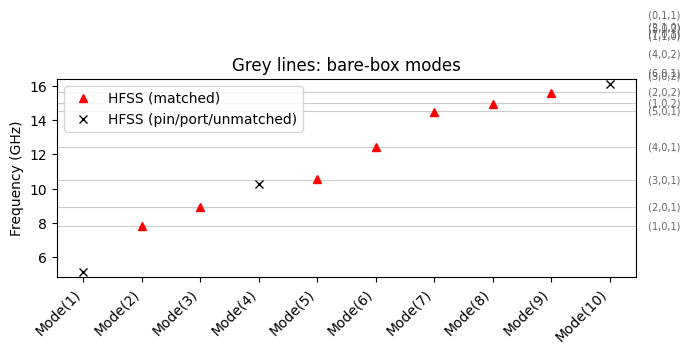

In [11]:
box = box_modes(15)
fig, ax = plt.subplots(figsize=(7, 4))
for _, r in box.iterrows():
    ax.axhline(r["f_box (GHz)"], color="0.8", lw=0.8, zorder=0)
    ax.text(len(cavity_matched) - 0.4, r["f_box (GHz)"], f' {r["mode (m,n,l)"]}', va="center", fontsize=7, color="0.4")
ok = cavity_matched["f_box (GHz)"].notna()
ax.plot(np.flatnonzero(ok), cavity_matched.loc[ok, "Frequency_Real (GHz)"], "r^", label="HFSS (matched)")
ax.plot(np.flatnonzero(~ok), cavity_matched.loc[~ok, "Frequency_Real (GHz)"], "kx", label="HFSS (pin/port/unmatched)")
ax.set_xticks(range(len(cavity_matched)))
ax.set_xticklabels(cavity_matched["Eigenmode"], rotation=45, ha="right")
ax.set_ylabel("Frequency (GHz)")
ax.set_ylim(cavity_matched["Frequency_Real (GHz)"].min() - 0.3, cavity_matched["Frequency_Real (GHz)"].max() + 0.3)
ax.set_title("Grey lines: bare-box modes")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(BASE / "figures/cavity_modes.pdf")
plt.show()

### Field plots
Mag_E of the two lowest cavity modes (the TE101/TE110 pair when `cav_W == cav_H`) on the seam plane
(`Global:XY`, z = 0, where the chips sit) and across the cavity (`Global:YZ`). Plots appear under
*Field Overlays* in AEDT and are exported as JPGs to `figures/`.

Note: in an eigenmode design **every** overlay shows whichever mode is currently selected in
*HFSS > Fields > Edit Sources*. The JPGs are exported right after each mode is selected, so they are
correct; in the AEDT window, call `show_mode(k, n_modes)` (or use Edit Sources) to switch what you see.

In [12]:
n_modes = len(cavity_results)
cavity_modes = cavity_matched.index[cavity_matched["f_box (GHz)"].notna()][:2]   # two lowest real cavity modes
for idx in cavity_modes:
    k = idx + 1                                   # HFSS mode numbers are 1-based
    show_mode(k, n_modes)
    for plane in ("Global:XY", "Global:YZ"):
        plot_field_cut(plane, "Mag_E", SETUP_EM_CAVITY, f"MagE_mode{k}_{plane.split(':')[1]}")
print("plotted modes:", [i + 1 for i in cavity_modes])
hfss.save_project()

PyAEDT INFO: Active Design set to EM_Cavity
PyAEDT INFO: Active Design set to EM_Cavity
PyAEDT INFO: Active Design set to EM_Cavity
PyAEDT INFO: Active Design set to EM_Cavity
plotted modes: [2, 3]
PyAEDT INFO: Project coffin_4Q Saved correctly


True

## Cavity + Transmons
Four **asymmetric transmons**, one chip per tunnel, built natively in HFSS. Pad / junction / chip dimensions
come from the previous cavity's transmon (positions from that design are not used):

| | |
|---|---|
| pad 1 (long, tip side) | 4000 × 200 µm |
| pad 2 (short, tunnel side) | 2000 × 200 µm |
| junction | 30 × 30 µm, with 85 µm × 30 µm leads each side (pad gap = 200 µm) |
| chip | sapphire, 16.63 mm long × 2.45 mm wide × 0.43 mm thick |
| mesh | jj 10 µm, pads 50 µm, substrate 0.5 mm |

Layout here: each chip is held by a clamp at its back end (clamp not modelled yet) and runs through its tunnel
into the cavity, bottom face at the tunnel-floor height (z = −`chip_T`). Near the cavity it passes between two
clearance pockets (Inventor `top_pocket_*` / `bot_pocket_*`, 2.43 mm deep each, 10 mm long), so the pads have
~2.4 mm of vacuum above and below instead of copper 0.07–0.5 mm away. Dipole along y. The long pad (pad 1) is at the chip tip inside the cavity
(65 µm from the tip, as in the old chip), how far each chip sticks into the cavity is set per qubit by `PROTRUDE_MM` (outer qubits protrude more, to even out g), and the short pad (pad 2) runs
back into the tunnel under the drive pin. The substrate is left **inside** the vacuum (not subtracted), as in the
old code, so the chip faces don't become PerfE. Junction inductances are design variables `Lj1..Lj4`; each
junction also gets a non-model line `jj_line_i` for pyEPR.

In [32]:
UM = 1e-3   # um -> mm

# Chip outline and the clearance pockets come from the Inventor parameters, so the simulated chip matches the
# machined part. Older params files lack these keys: rerun inventor_coffin_4q.py.
_missing = [k for k in ("chip_W", "chip_L", "chip_thk", "top_pocket_D", "bot_pocket_D", "bot_pocket_L")
            if k not in P]
assert not _missing, (f"{PARAMS.name} has no {_missing}: rerun inventor_coffin_4q.py (adds the clearance pockets and "
                      f"exports a new coffin_4Q_hfss.stp + params), then rerun the setup cells")

CHIP = {
    "material":   "sapphire",
    "L":          P["chip_L"],    # mm, chip length (along the tunnel, y)
    "W":          P["chip_W"],    # mm, chip width (x)
    "T":          P["chip_thk"],  # mm, chip thickness (bottom face at the tunnel-floor height, held by the clamp)
    "pad_margin": 65 * UM,        # chip tip to pad 1 (old chip: half-length - 5.5 * 1500 um)
    "pad1_L":     4000 * UM,      # pad 1: long pad (tip / cavity side)   [was 2000 um]
    "pad2_L":     2000 * UM,      # pad 2: short pad (tunnel / drive side) [was 4000 um]
    "pad_W":      200 * UM,
    "jj_L":       30 * UM,        # junction length (along the dipole, y)
    "jj_W":       30 * UM,        # junction width (x) = lead width
    "lead_L":     85 * UM,
}
CHIP["pad_gap"] = CHIP["jj_L"] + 2 * CHIP["lead_L"]       # 200 um

# How far each chip tip sticks past the cavity -y wall (mm), per qubit Q1..Q4. The outer qubits sit where the TE101
# field (~cos(pi x / cav_L)) is weaker, so they protrude more to get g / chi / Purcell similar to the inner ones.
# Starting guess from the field ratio (~1.4x in g) and the qubit detunings, with g ~ exp(K * protrude) for the
# evanescent field in the tunnel; refine with the suggestion printed by the "Dispersive shift to readout" cell.
# The junction sits ~4.17 mm behind the tip (65 um margin + 4 mm pad 1 + lead), so it is inside the cavity
# once protrude > ~4.2 mm.
# Previous values: 1.0 mm for every qubit; then 2.5 / 2.1 / 2.1 / 2.5 with a 7.75 GHz readout mode.
# 7.25 GHz readout: smaller detuning and a slightly larger mode volume raise chi by ~1.17-1.25x at the same geometry.
# From the 0.8 -> 2.1 mm protrude runs, chi grows ~3.7x per mm of protrude here, so ~0.15 mm less protrude keeps chi
# the same. Pulled back 0.2 mm (0.7 mm would cut chi to ~half of today's values, below kappa).
PROTRUDE_MM = [2.3, 1.9, 1.9, 2.3]

# Metal mark on each chip where the clamp grips it: a strip across the full chip width on the top surface,
# CLAMP_MARK_L long, starting CLAMP_FROM_TIP_MM from the transmon (tip) edge of the chip.
CLAMP_FROM_TIP_MM = 18.6
CLAMP_MARK_L = 0.5

# Junction inductances (nH), staggered 200 MHz across 4.2-4.8 GHz. 200 MHz (> |alpha| ~ 100 MHz) keeps each qubit's
# f12 away from its neighbour's f01. Chosen by scaling the 11-14 nH run
# (f_lin ~ 1/sqrt(L_J), C_pad ~ 195 fF, E_C ~ 100 MHz, f01 ~ f_lin - E_C) to the targets below.
# Previous values: [11.0, 12.0, 13.0, 14.0] -> f01 ~ 3.32 / 3.21 / 3.07 / 2.96 GHz;
#                  [7.12, 7.61, 7.94, 8.41] -> targets 4.15 / 4.05 / 3.95 / 3.85 GHz.
LJ_NH =[10, 11, 12, 13]
QUBIT_F_TARGET_GHZ = [4.8, 4.6, 4.4, 4.2]   # f01 targets (GHz), checked after EPR ("Qubit frequency check")
CJ_FF = None                        # junction capacitance (fF) or None
JJ_PORT_Z = 1e6                     # ohm, driven-modal junction port (SNAIL value; essentially open)
CJ_BBQ_FF = CJ_FF if CJ_FF is not None else 4.0   # fF, junction capacitance added in BBQ (SNAIL: 4 fF)

MESH = {"substrate": "0.5mm", "pads": "50um", "jj": "10um"}


def chip_layout(i):
    # Geometry (mm, global coords) of chip i (1..4). Rectangles are (origin, [dx, dy]) in the plane z = z_top.
    c = CHIP
    x = QUBIT_X[i - 1]
    z_floor = -P["chip_T"]                       # chip bottom face = tunnel-floor height (clamped at the back)
    z_top = z_floor + c["T"]                     # chip top surface = pad plane
    y_tip = -P["cav_W"] / 2 + PROTRUDE_MM[i - 1]
    y_back = y_tip - c["L"]
    y_p1_hi = y_tip - c["pad_margin"]            # pad 1, tip side
    y_p1_lo = y_p1_hi - c["pad1_L"]
    y_jj_hi = y_p1_lo - c["lead_L"]
    y_jj_lo = y_jj_hi - c["jj_L"]
    y_p2_hi = y_p1_lo - c["pad_gap"]             # pad 2, tunnel side
    y_p2_lo = y_p2_hi - c["pad2_L"]
    xp, xj = x - c["pad_W"] / 2, x - c["jj_W"] / 2
    return dict(
        x=x, z_floor=z_floor, z_top=z_top, y_tip=y_tip, y_back=y_back, y_jj=(y_jj_lo + y_jj_hi) / 2,
        pad1=([xp, y_p1_lo, z_top], [c["pad_W"], c["pad1_L"]]),
        lead1=([xj, y_jj_hi, z_top], [c["jj_W"], c["lead_L"]]),
        jj=([xj, y_jj_lo, z_top], [c["jj_W"], c["jj_L"]]),
        lead2=([xj, y_p2_hi, z_top], [c["jj_W"], c["lead_L"]]),
        pad2=([xp, y_p2_lo, z_top], [c["pad_W"], c["pad2_L"]]),
        line=([x, y_jj_lo, z_top], [x, y_jj_hi, z_top]),
        clamp=([x - c["W"] / 2, y_tip - CLAMP_FROM_TIP_MM - CLAMP_MARK_L, z_top], [c["W"], CLAMP_MARK_L]),
    )


# sanity checks before touching HFSS
assert CHIP["W"] < P["tunnel_W"], "chip wider than the tunnel"
assert CHIP["T"] <= P["chip_T"] + 1e-9, "chip thicker than the tunnel"
_z_top = -P["chip_T"] + CHIP["T"]
print(f"[chips] chip {CHIP['W']} x {CHIP['T']} x {CHIP['L']} mm in a {P['tunnel_W']} mm tunnel; near the cavity "
      f"{(P['top_pocket_D'] - _z_top):.2f} mm vacuum above the pads, {P['bot_pocket_D']:.2f} mm below the chip "
      f"(pockets {P['top_pocket_L']:g} / {P['bot_pocket_L']:g} mm long)")
for i in range(1, 5):
    L = chip_layout(i)
    assert L["y_tip"] < P["cav_W"] / 2, f"chip {i} crosses the whole cavity"
    assert L["y_back"] > -(P["cav_W"] / 2 + P["tunnel_L"]), f"chip {i} longer than the tunnel"
    assert L["pad2"][0][1] > L["y_back"], f"chip {i}: pad 2 runs off the chip"
    assert L["pad2"][0][1] > -(P["cav_W"] / 2 + min(P["top_pocket_L"], P["bot_pocket_L"])), \
        f"chip {i}: pad 2 extends past the clearance pockets (pads would sit next to the tunnel walls)"
    assert P["cav_W"] / 2 - L["y_tip"] >= 1.0, f"chip {i} tip is within 1 mm of the +y (readout) wall"
    assert L["clamp"][0][1] > L["y_back"], f"chip {i}: clamp mark runs off the back of the chip"
    assert CLAMP_FROM_TIP_MM > CHIP["pad_margin"] + CHIP["pad1_L"] + CHIP["pad_gap"] + CHIP["pad2_L"], "clamp mark overlaps the pads"
lay = pd.DataFrame({f"Q{i}": {k: chip_layout(i)[k] for k in ("x", "y_tip", "y_jj", "y_back", "z_top")}
                    for i in range(1, 5)}).round(3)
lay.loc["protrude (mm)"] = PROTRUDE_MM
lay.loc["clamp mark y (start)"] = [round(chip_layout(i)["y_tip"] - CLAMP_FROM_TIP_MM, 3) for i in range(1, 5)]
lay.loc["jj to cavity wall (mm, + = inside)"] = lay.loc["y_jj"] + P["cav_W"] / 2
lay.loc["drive pin y"] = Y_DRIVES
lay.loc["pad 2 end to drive pin (mm, y)"] = lay.loc["y_jj"] - 0.1 - CHIP["pad2_L"] - lay.loc["drive pin y"]
lay

[chips] chip 2.45 x 0.43 x 16.63 mm in a 3.45 mm tunnel; near the cavity 2.50 mm vacuum above the pads, 2.43 mm below the chip (pockets 10 / 10 mm long)


,Q1,Q2,Q3,Q4
x,-15.750,-5.250,5.250,15.750
y_tip,-1.500,-1.900,-1.900,-1.500
y_jj,-5.665,-6.065,-6.065,-5.665
y_back,-18.130,-18.530,-18.530,-18.130
z_top,-0.070,-0.070,-0.070,-0.070
protrude (mm),2.500,2.100,2.100,2.500
"jj to cavity wall (mm, + = inside)",-1.665,-2.065,-2.065,-1.665
drive pin y,-10.500,-10.500,-10.500,-10.500
"pad 2 end to drive pin (mm, y)",2.735,2.335,2.335,2.735


In [33]:
def add_transmons(junction="rlc", port_qubits=None):
    # Add the 4 chips to the active design (call after build_cavity()). Returns pyEPR junction info.
    # junction="rlc": each jj sheet is a lumped inductor Lj_i (eigenmode / pyEPR).
    # junction="port": each jj sheet is a lumped port jj_i of JJ_PORT_Z (driven modal / BBQ).
    # junction="mixed": qubits in port_qubits get lumped ports, the rest stay lumped inductors Lj_i.
    assert junction in ("rlc", "port", "mixed"), junction
    port_set = (set(range(1, 5)) if junction == "port"
                else set(port_qubits or ()) if junction == "mixed" else set())
    assert junction != "mixed" or port_set, "junction='mixed' needs port_qubits, e.g. [1]"
    for op in list(getattr(hfss.mesh, "meshoperations", [])):    # clean rerun
        try:
            op.delete()
        except Exception:
            pass

    omodule = hfss.odesign.GetModule("BoundarySetup")
    subs, pads, jjs, junctions = [], [], [], {}
    for i in range(1, 5):
        L = chip_layout(i)
        if i not in port_set:
            hfss[f"Lj{i}"] = f"{LJ_NH[i - 1]}nH"                 # design variable (pyEPR / sweeps)

        sub = hfss.modeler.create_box(origin=[L["x"] - CHIP["W"] / 2, L["y_back"], L["z_floor"]],
                                      sizes=[CHIP["W"], CHIP["L"], CHIP["T"]],
                                      name=f"substrate_{i}", material=CHIP["material"])
        sub.transparency = 0.9

        # pads + leads (united), junction sheet, pyEPR line
        p1 = hfss.modeler.create_rectangle("XY", *L["pad1"], name=f"pad_{i}a")
        l1 = hfss.modeler.create_rectangle("XY", *L["lead1"], name=f"lead_{i}a")
        p2 = hfss.modeler.create_rectangle("XY", *L["pad2"], name=f"pad_{i}b")
        l2 = hfss.modeler.create_rectangle("XY", *L["lead2"], name=f"lead_{i}b")
        hfss.modeler.unite([p1.name, l1.name])
        hfss.modeler.unite([p2.name, l2.name])
        jj = hfss.modeler.create_rectangle("XY", *L["jj"], name=f"jj_{i}")
        hfss.modeler.create_polyline(list(L["line"]), name=f"jj_line_{i}", non_model=True)

        hfss.assign_perfecte_to_sheets([p1.name, p2.name], f"pads_{i}")
        cm = hfss.modeler.create_rectangle("XY", *L["clamp"], name=f"clamp_mark_{i}")   # where the clamp grips
        hfss.assign_perfecte_to_sheets([cm.name], f"clamp_mark_{i}")
        if i in port_set:
            # same call as the SNAIL notebook; the integration line is the jj current line (along y)
            hfss._create_lumped_driven(assignment=jj.name, int_line_start=L["line"][0],
                                       int_line_stop=L["line"][1], impedance=JJ_PORT_Z,
                                       port_name=f"jj{i}", renorm=False, deemb=False)
        else:
            start, end = ([f"{v}mm" for v in pt] for pt in L["line"])
            rlc = ["NAME:jj" + str(i), "Objects:=", [jj.name],
                   ["NAME:CurrentLine", "Start:=", start, "End:=", end],
                   "RLC Type:=", "Parallel", "UseResist:=", False,
                   "UseInduct:=", True, "Inductance:=", f"Lj{i}",
                   "UseCap:=", CJ_FF is not None]
            if CJ_FF is not None:
                rlc += ["Capacitance:=", f"{CJ_FF}fF"]
            omodule.AssignLumpedRLC(rlc)

        subs.append(sub.name); pads += [p1.name, p2.name]; jjs.append(jj.name)
        junctions[f"j{i}"] = {"Lj_variable": f"Lj{i}", "rect": jj.name, "line": f"jj_line_{i}",
                              "length": f"{CHIP['jj_L']}mm"}

    hfss.mesh.assign_length_mesh(subs, inside_selection=False, maximum_length=MESH["substrate"],
                                 maximum_elements=None, name="tmon_substrate")
    hfss.mesh.assign_length_mesh(pads, inside_selection=False, maximum_length=MESH["pads"],
                                 maximum_elements=None, name="tmon_pads")
    hfss.mesh.assign_length_mesh(jjs, inside_selection=False, maximum_length=MESH["jj"],
                                 maximum_elements=None, name="tmon_jj")
    hfss.modeler.fit_all()
    kinds = {i: ("port" if i in port_set else "Lj") for i in range(1, 5)}
    print(f"[chips] {len(subs)} asymmetric transmons; junctions: "
          + ", ".join(f"Q{i}={k}" for i, k in kinds.items())
          + f" (ports {JJ_PORT_Z:g} ohm, Lj = {LJ_NH} nH)")
    return junctions

In [34]:
use_design("EM_Cavity_with_Transmons")
ports = build_cavity()
JUNCTIONS = add_transmons()

PyAEDT INFO: Python version 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)].
PyAEDT INFO: PyAEDT version 0.24.1.
PyAEDT INFO: Returning found Desktop session with PID 17124!
PyAEDT INFO: Project coffin_4Q set to active.
PyAEDT INFO: Active Design set to EM_Cavity_with_Transmons
PyAEDT INFO: Aedt Objects correctly read
PyAEDT INFO: Modeler class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Deleted 21 Objects: cavity,substrate_1,substrate_2,substrate_3,substrate_4,pad_1a,pad_1b,jj_1,pad_2a,pad_2b,jj_2,pad_3a,pad_3b,jj_3,pad_4a,pad_4b,jj_4,jj_line_1,jj_line_2,jj_line_3,jj_line_4.
PyAEDT INFO: Step file C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\inventor_files\coffin_4Q_hfss.stp imported
PyAEDT INFO: Mate

Setup: `MinimumFrequency = 2 GHz` so the qubits (targets 4.2–4.8 GHz, see `QUBIT_F_TARGET_GHZ`) are included. `NumModes = 12` = 4 qubits + the first cavity modes,
with room for any low-Q pin modes (there should be none with the matched port termination; if there are,
check the convergence table in AEDT, since they converge slowly).

In [35]:
SETUP_EM_TRANSMONS = "EM_Cavity_with_Transmons"
eigen_setup(SETUP_EM_TRANSMONS,
            MinimumFrequency="2GHz",
            NumModes=12,
            MaxDeltaFreq=0.1,
            ConvergeOnRealFreq=True,
            MaximumPasses=20,
            MinimumPasses=2,
            MinimumConvergedPasses=2,
            BasisOrder=-1)
hfss.analyze(setup=SETUP_EM_TRANSMONS, cores=num_cores)
hfss.save_project()

PyAEDT INFO: Parsing C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt.
PyAEDT INFO: File C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt correctly loaded. Elapsed time: 0m 1sec
PyAEDT INFO: aedt file load time 0.9231812953948975
PyAEDT INFO: Project coffin_4Q Saved correctly
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT INFO: Solving design setup EM_Cavity_with_Transmons
PyAEDT INFO: Design setup EM_Cavity_with_Transmons solved correctly in 0.0h 40.0m 10.0s
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT INFO: Project coffin_4Q Saved correctly


True

### Results
Modes are labeled with the nearest bare-box mode where it fits; low-Q modes are the drive pins.
The rest are **qubit-like** (high Q, no box match). EPR below gives the definitive junction participation.

In [36]:
tm_results = eigenmode_results("cavity_transmons_eigenmode_results.csv")
tm_matched = match_box_modes(tm_results)
tm_matched["box mode"] = tm_matched["box mode"].replace("unmatched", "qubit-like")
tm_matched

PyAEDT INFO: Parsing C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt.


INFO 02:07PM [__del__]: Disconnected from Ansys HFSS


PyAEDT INFO: File C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt correctly loaded. Elapsed time: 0m 2sec
PyAEDT INFO: aedt file load time 2.122269868850708
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 5sec
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 3sec
PyAEDT INFO: Post class has been initialized! Elapsed time: 0m 3sec
PyAEDT WARNING: No report category provided. Automatically identified Eigenmode Parameters
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.07890033721923828
Time to initialize solution data:0.07990026473999023
PyAEDT WARNING: No report category provided. Automatically identified Eigenmode Parameters
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.08521866798400879
Time to initialize solution data:0.08621859550476074
PyAEDT WARNING: No report category provided. Automatically identified Eigenmode Parameters
PyAEDT INFO: 

,Eigenmode,Frequency_Real (GHz),Frequency_Imag (GHz),Q,box mode,f_box (GHz),f - f_box (MHz)
0,Mode(1),4.084687,0.000009,226894.315590,qubit-like,NaN,NaN
1,Mode(2),4.241051,0.000028,74522.312244,qubit-like,NaN,NaN
2,Mode(3),4.418254,0.000017,129462.437637,qubit-like,NaN,NaN
3,Mode(4),4.632910,0.000016,147183.417282,qubit-like,NaN,NaN
4,Mode(5),5.159706,9.372819,0.570755,pin/port mode (low Q),NaN,NaN
5,Mode(6),5.196353,9.411023,0.571156,pin/port mode (low Q),NaN,NaN
6,Mode(7),5.407013,9.674680,0.572789,pin/port mode (low Q),NaN,NaN
7,Mode(8),5.422648,9.696867,0.572871,pin/port mode (low Q),NaN,NaN
8,Mode(9),7.755299,0.000063,61639.400550,"(1,0,1)",7.805580,-50.280407
9,Mode(10),8.855922,0.000063,70568.981378,"(2,0,1)",8.924749,-68.826432


In [37]:
# Mag_E on the seam plane for every qubit-like mode
n_modes = len(tm_results)
qubit_modes = [i + 1 for i in tm_matched.index[tm_matched["box mode"] == "qubit-like"]]
for k in qubit_modes:
    show_mode(k, n_modes)
    plot_field_cut("Global:XY", "Mag_E", SETUP_EM_TRANSMONS, f"TM_MagE_mode{k}_XY")
print("qubit-like modes:", qubit_modes)
hfss.save_project()

PyAEDT INFO: Active Design set to EM_Cavity_with_Transmons
PyAEDT INFO: Active Design set to EM_Cavity_with_Transmons
PyAEDT INFO: Active Design set to EM_Cavity_with_Transmons
PyAEDT INFO: Active Design set to EM_Cavity_with_Transmons
qubit-like modes: [1, 2, 3, 4]
PyAEDT INFO: Project coffin_4Q Saved correctly


True

### EPR (pyEPR 0.8)
Energy-participation analysis of all four junctions: qubit frequencies, anharmonicities, cross-Kerrs and
dispersive shifts. Set `RUN_EPR = True` once the eigenmode solve above has converged.
pyEPR 0.8 needs the numpy 2 / pandas 2 compatibility patches, applied here before it is imported.

In [38]:
RUN_EPR = True

if RUN_EPR:
    # --- pyEPR 0.8 compat (removed numpy aliases, pandas .append / .iteritems) ---
    for alias, target in {"float": float, "int": int, "complex": complex, "bool": bool, "object": object,
                          "str": str, "float_": np.float64, "complex_": np.complex128,
                          "NaN": np.nan, "Inf": np.inf, "infty": np.inf, "product": np.prod,
                          "cumproduct": np.cumprod, "alltrue": np.all, "sometrue": np.any}.items():
        if alias not in np.__dict__:
            setattr(np, alias, target)
    if not hasattr(pd.DataFrame, "append"):
        def _df_append(self, other, ignore_index=False, verify_integrity=False, sort=False):
            if isinstance(other, pd.Series):
                other = other.to_frame().T
            elif isinstance(other, dict):
                other = pd.DataFrame([other])
            elif isinstance(other, (list, tuple)):
                return pd.concat([self, *other], ignore_index=ignore_index, sort=sort)
            return pd.concat([self, other], ignore_index=ignore_index, sort=sort)
        pd.DataFrame.append = _df_append
    if not hasattr(pd.Series, "append"):
        pd.Series.append = lambda self, o, ignore_index=False, verify_integrity=False: pd.concat(
            [self, *(o if isinstance(o, (list, tuple)) else [o])], ignore_index=ignore_index)
    for cls in (pd.DataFrame, pd.Series):
        if not hasattr(cls, "iteritems"):
            cls.iteritems = cls.items
    # pandas 2: drop(labels, axis) no longer takes axis positionally (pyEPR ansys.py: .drop('Unnamed: 3', 1))
    if not getattr(pd.DataFrame.drop, "_epr_compat", False):
        _df_drop = pd.DataFrame.drop

        def _drop_compat(self, labels=None, *args, **kwargs):
            if args:
                kwargs.setdefault("axis", args[0])
            return _df_drop(self, labels, **kwargs)
        _drop_compat._epr_compat = True
        pd.DataFrame.drop = _drop_compat

    import pyEPR as epr
    # pint >= 0.2x parses "0" as Quantity(0), which pyEPR 0.8 uses as a tuple index for variations.
    # Wrap its registry: calling it with a variation string gives an int; .Quantity etc. pass through.
    import pyEPR.core_distributed_analysis as _epr_cda

    class _VariationUreg:
        def __init__(self, ureg):
            self._ureg = ureg

        def __call__(self, s):
            return int(s) if str(s).strip().isdigit() else self._ureg(s)

        def __getattr__(self, name):
            return getattr(self._ureg, name)

    if not isinstance(_epr_cda.ureg, _VariationUreg):
        _epr_cda.ureg = _VariationUreg(epr.ansys.ureg)
    # pyEPR styles its 'Freq. vs. pass' HFSS report (line width, axis units) with ChangeProperty, which
    # AEDT 2023.2 rejects. Cosmetic only (the report data is not used), so log and carry on.
    if not getattr(_epr_cda.set_property, "_epr_compat", False):
        _set_property = _epr_cda.set_property

        def _set_property_compat(*args, **kwargs):
            try:
                return _set_property(*args, **kwargs)
            except Exception as e:
                print(f"[epr] skipped HFSS report styling {args[1:4]}: {e}")
        _set_property_compat._epr_compat = True
        _epr_cda.set_property = _set_property_compat
    # pyEPR make_dispersive fixes, recompiled in its own module:
    #  - QuTiP 5: bra * ket is a complex number, not a 1x1 Qobj, so .norm() fails. Use abs(<a|b>) (same value).
    #  - N = int(log(dim) / log(fock_trunc)) truncates 4.999999999999999 to 4 for 3^5 (also 9^5, 10^3, 10^6).
    # _epr_compat is a patch version: bump it when this list changes, so a running kernel re-patches.
    import importlib
    import inspect
    import pyEPR.calcs.back_box_numeric as _epr_bbn
    if getattr(_epr_bbn.make_dispersive, "_epr_compat", 0) != 2:
        importlib.reload(_epr_bbn)                              # back to the installed source
        _src, _first = inspect.getsourcelines(_epr_bbn.make_dispersive)
        _src = "".join(_src)
        for _old, _new in [("(s.dag() * s2[1]).norm()", "abs(s.overlap(s2[1]))"),
                           ("(vector1.dag() * evec).norm()", "abs(vector1.overlap(evec))"),
                           ("N = int(np.log(H.shape[0]) / np.log(fock_trunc))",
                            "N = int(round(np.log(H.shape[0]) / np.log(fock_trunc)))")]:
            assert _old in _src, f"pyEPR make_dispersive changed; patch not applied ({_old})"
            _src = _src.replace(_old, _new)
        # leading newlines keep traceback line numbers matching the installed file
        exec(compile("\n" * (_first - 1) + _src, _epr_bbn.__file__, "exec"), _epr_bbn.__dict__)
        _epr_bbn.make_dispersive._epr_compat = 2
    # pyEPR's _config_user.py saves to D:\data-pyEPR (no D: drive here); keep results with the project
    epr.config.root_dir = str(BASE / "data" / "pyEPR")

    hfss.save_project()
    pinfo = epr.ProjectInfo(project_path=str(AEDT.parent), project_name=NAME,
                            design_name="EM_Cavity_with_Transmons", setup_name=SETUP_EM_TRANSMONS)
    for name, j in JUNCTIONS.items():
        pinfo.junctions[name] = {**j, "length": epr.parse_units(j["length"])}
    pinfo.validate_junction_info()
    pinfo.dissipative["dielectrics_bulk"] = [f"substrate_{i}" for i in range(1, 5)]

    # Modes for EPR + numerical diagonalization: all four qubits + the readout mode (5x5 chi matrix).
    # Qubits = the qubit-like modes; readout = lowest cavity (box-matched, high-Q) mode. The low-Q drive-pin
    # modes and the other cavity modes are left out. Indices are 0-based HFSS mode numbers (Mode(k) -> k - 1).
    # fock_trunc = 5 keeps |0>..|4> per mode (5^5 = 3125 states, ~3 min). Below 5 the ND anharmonicity is wrong:
    # about -64 MHz at 3 and -3 MHz at 4, vs +81 MHz at 5 and +85 MHz at 1st order. ZZ is not converged at 5.
    EPR_FOCK_TRUNC = 5
    ZZ_FLAG_KHZ = 50.0            # flag |chi_ij| between qubits above this (kHz)
    CROSS_P_FLAG = 1e-3           # flag a qubit's participation in another junction above this (relative to its own)
    if "tm_matched" not in globals():
        tm_matched = match_box_modes(pd.read_csv(BASE / "data/eigenmode/cavity_transmons_eigenmode_results.csv"))
        tm_matched["box mode"] = tm_matched["box mode"].replace("unmatched", "qubit-like")
    labels = tm_matched["box mode"]
    qubit_modes = [int(k) for k in tm_matched.index[labels == "qubit-like"]]
    readout_mode = int(tm_matched.index[~labels.isin(["qubit-like", "pin/port mode (low Q)"])][0])
    f_col = tm_matched["Frequency_Real (GHz)"]
    if len(qubit_modes) != len(JUNCTIONS):
        raise RuntimeError(
            f"found {len(qubit_modes)} qubit-like modes "
            f"{[f'Mode({k + 1}) {f_col[k]:.4f} GHz' for k in qubit_modes]}, expected {len(JUNCTIONS)}. "
            f"Lower MinimumFrequency / raise NumModes in the eigenmode setup and re-solve, or check tm_matched.")
    EPR_MODES = sorted(qubit_modes + [readout_mode])
    print(f"[epr] qubit modes = {[f'Mode({k + 1}) {f_col[k]:.4f} GHz' for k in qubit_modes]}, "
          f"readout = Mode({readout_mode + 1}) {labels[readout_mode]} at {f_col[readout_mode]:.4f} GHz")

    # Check the readout choice: it must sit near READOUT_F_GHZ (default: lowest analytic box mode, the
    # (1,0,1) at ~7.8 GHz for 50 x 15 x 20.8 mm). Otherwise a different mode was picked; stop before EPR.
    READOUT_F_GHZ = None          # GHz, or None for the lowest bare-box mode
    READOUT_TOL = 0.03            # relative
    box0 = box_modes(1).iloc[0]
    f_target = READOUT_F_GHZ if READOUT_F_GHZ is not None else box0["f_box (GHz)"]
    target_src = "READOUT_F_GHZ" if READOUT_F_GHZ is not None else f"{box0['mode (m,n,l)']} bare box"
    f_ro = f_col[readout_mode]
    if abs(f_ro - f_target) / f_target > READOUT_TOL:
        near = tm_matched.loc[(f_col - f_target).abs().idxmin()]
        raise RuntimeError(
            f"readout pick Mode({readout_mode + 1}) at {f_ro:.4f} GHz is not within {READOUT_TOL:.0%} of the expected "
            f"{f_target:.4f} GHz ({target_src}). Closest HFSS mode: {near['Eigenmode']} at "
            f"{near['Frequency_Real (GHz)']:.4f} GHz, Q = {near['Q']:.3g}, labelled '{near['box mode']}'. "
            f"Check tm_matched, or set READOUT_F_GHZ.")
    print(f"[epr] readout check ok: {f_ro:.4f} GHz vs expected {f_target:.4f} GHz "
          f"({(f_ro - f_target) / f_target:+.2%})")

    eprd = epr.DistributedAnalysis(pinfo)
    eprd.do_EPR_analysis(modes=EPR_MODES)
    epra = epr.QuantumAnalysis(eprd.data_filename)
    epra.analyze_all_variations(cos_trunc=8, fock_trunc=EPR_FOCK_TRUNC)
    epra.report_results(numeric=True)

    # ---- label qubits by junction, cross participation, ZZ ----
    res = epra.results[list(epra.results.keys())[0]]            # single variation
    Pm = pd.DataFrame(res["Pm_raw"]).astype(float)              # rows: HFSS mode index, cols: j1..j4
    pos = {m: k for k, m in enumerate(EPR_MODES)}               # HFSS mode -> row/col in the chi matrices
    jnames = list(Pm.columns)

    qubit_of = {}                                               # HFSS mode -> "Q<i>"
    for m in qubit_modes:
        jdom = Pm.loc[m].idxmax()
        qubit_of[m] = "Q" + jdom.lstrip("j")
    if len(set(qubit_of.values())) != len(qubit_modes):
        print(f"[epr] WARNING: junction labels are not unique: {qubit_of}. Two modes share a junction "
              f"(hybridized qubits?); check the participation table below.")
    order = sorted(qubit_modes, key=lambda m: qubit_of[m])      # Q1, Q2, Q3, Q4
    names = [qubit_of[m] for m in order]

    # cross participation: each qubit mode's participation in the other junctions, relative to its own
    own = {m: Pm.loc[m, "j" + qubit_of[m][1:]] for m in order}
    cross = pd.DataFrame({j: [Pm.loc[m, j] / own[m] for m in order] for j in jnames}, index=names)
    cross.index.name = "qubit mode"
    for m, q in zip(order, names):
        cross.loc[q, "j" + q[1:]] = np.nan                      # own junction: not crosstalk
    flagged = cross[cross > CROSS_P_FLAG].stack()
    print("\n[epr] qubit modes labelled by junction:")
    for m, q in zip(order, names):
        print(f"   {q}: Mode({m + 1}) at {res['f_ND'].iloc[pos[m]].real / 1e3:.4f} GHz (ND), "
              f"p_own = {own[m]:.4f} in j{q[1:]}")
    print(f"\n[epr] cross participation p(other junction) / p(own junction)  [flag > {CROSS_P_FLAG:g}]")
    print(cross.map(lambda v: "" if pd.isna(v) else f"{v:.2e}").to_string())
    if flagged.empty:
        print(f"   OK: no qubit puts more than {CROSS_P_FLAG:g} of its junction energy into another junction")
    else:
        for (q, j), v in flagged.items():
            print(f"   FLAG: {q} -> {j}: {v:.2e} (> {CROSS_P_FLAG:g})")

    # ZZ (qubit-qubit cross-Kerr) and dispersive shift to readout, kHz
    def _khz(chi):
        a = np.real(np.asarray(chi, dtype=complex)) * 1e3     # pyEPR chi in MHz
        return pd.DataFrame(a[np.ix_([pos[m] for m in order], [pos[m] for m in order])], index=names, columns=names)
    zz = {"chi_O1 (1st order)": _khz(res["chi_O1"]), "chi_ND (numerical)": _khz(res["chi_ND"])}
    for key, df in zz.items():
        off = df.where(~np.eye(len(df), dtype=bool))
        print(f"\n[epr] ZZ {key}, kHz (diagonal = anharmonicity)  [flag |ZZ| > {ZZ_FLAG_KHZ:g} kHz]")
        print(df.map(lambda v: f"{v:.3g}").to_string())
        bad = off[off.abs() > ZZ_FLAG_KHZ].stack()
        print("   OK: all |ZZ| below threshold" if bad.empty else
              "\n".join(f"   FLAG: {a}-{b}: {v:.3g} kHz" for (a, b), v in bad.items() if a < b))
    chi_ro = pd.Series({q: np.real(complex(np.asarray(res["chi_ND"], dtype=complex)[pos[m], pos[readout_mode]])) * 1e3
                        for m, q in zip(order, names)}, name="chi to readout (kHz)")
    print("\n[epr] dispersive shift to readout (ND), kHz"); print(chi_ro.round(2).to_string())

    out = BASE / "data" / "pyEPR"
    cross.to_csv(out / "cross_participation.csv")
    zz["chi_ND (numerical)"].to_csv(out / "zz_chi_ND_kHz.csv")
    zz["chi_O1 (1st order)"].to_csv(out / "zz_chi_O1_kHz.csv")
    chi_ro.to_csv(out / "chi_readout_kHz.csv")

PyAEDT INFO: Project coffin_4Q Saved correctly


INFO 02:10PM [connect]: Connecting to Ansys Desktop API...
INFO 02:10PM [load_ansys_project]: 	File path to HFSS project found.
INFO 02:10PM [load_ansys_project]: 	Opened Ansys App
INFO 02:10PM [load_ansys_project]: 	Opened Ansys Desktop v2023.2.0
INFO 02:10PM [load_ansys_project]: 	Opened Ansys Project
	Folder:    C:/Users/epm114/Documents/GitHub/Cavity work/coffin_4Q/hfss_files/
	Project:   coffin_4Q
INFO 02:10PM [connect]: 	Opened active design
	Design:    EM_Cavity_with_Transmons [Solution type: Eigenmode]
INFO 02:10PM [get_setup]: 	Opened setup `EM_Cavity_with_Transmons`  (<class 'pyEPR.ansys.HfssEMSetup'>)
INFO 02:10PM [connect]: 	Connection to Ansys established successfully. 😀 



[epr] qubit modes = ['Mode(1) 4.0847 GHz', 'Mode(2) 4.2411 GHz', 'Mode(3) 4.4183 GHz', 'Mode(4) 4.6329 GHz'], readout = Mode(9) (1,0,1) at 7.7553 GHz
[epr] readout check ok: 7.7553 GHz vs expected 7.8056 GHz (-0.64%)
Design "EM_Cavity_with_Transmons" info:
	# eigenmodes    12
	# variations    1

Variation 0  [1/1]

  Mode 0 at 4.08 GHz   [1/12]
    Calculating ℰ_magnetic,ℰ_electric
       (ℰ_E-ℰ_H)/ℰ_E       ℰ_E       ℰ_H
               93.2%  1.125e-23 7.686e-25

    Calculating junction energy participation ration (EPR)
	method=`line_voltage`. First estimates:
	junction        EPR p_0j   sign s_0j    (p_capacitive)
		Energy fraction (Lj over Lj&Cj)= 98.70%
	j1              1.27752e-08  (+)        1.68296e-10
		Energy fraction (Lj over Lj&Cj)= 98.57%
	j2              3.17299e-07  (+)        4.59799e-09
		Energy fraction (Lj over Lj&Cj)= 98.44%
	j3              1.93933e-06  (+)        3.06577e-08
		Energy fraction (Lj over Lj&Cj)= 98.32%
	j4              0.931763  (+)        0.0159572


WARNING 02:12PM [__init__]: <p>Error: <class 'IndexError'></p>


[epr] skipped HFSS report styling ('Attributes', ['Freq. vs. pass:re(Mode(1)):Curve1', 'Freq. vs. pass:re(Mode(2)):Curve1', 'Freq. vs. pass:re(Mode(3)):Curve1', 'Freq. vs. pass:re(Mode(4)):Curve1', 'Freq. vs. pass:re(Mode(5)):Curve1', 'Freq. vs. pass:re(Mode(6)):Curve1', 'Freq. vs. pass:re(Mode(7)):Curve1', 'Freq. vs. pass:re(Mode(8)):Curve1', 'Freq. vs. pass:re(Mode(9)):Curve1', 'Freq. vs. pass:re(Mode(10)):Curve1', 'Freq. vs. pass:re(Mode(11)):Curve1', 'Freq. vs. pass:re(Mode(12)):Curve1'], 'Line Width'): (-2147352567, 'Exception occurred.', (0, None, None, None, 0, -2147024382), None)

ANALYSIS DONE. Data saved to:

C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\data\pyEPR\coffin_4Q\EM_Cavity_with_Transmons\2026-11-18 14-10-07.npz


	 Differences in variations:



 . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . 
Variation 0

Starting the diagonalization
Finished the diagonalization
Pm_norm=
modes
0    1.016449
1    1.016570
2    1.017421
3   

#### Mode frequencies (MHz)

... (2 outputs left out)

#### Kerr Non-linear coefficient table (MHz)

###### Numerical diagonalization

0                               1  \
variation                                                                     
0         0  1.32e+02+0.00e+            00j  3.88e-02+0.00e+            00j   
          1  3.88e-02+0.00e+            00j  1.31e+02+0.00e+            00j   
          2  9.34e-04+0.00e+            00j  2.20e-02+0.00e+            00j   
          3  8.00e-05+0.00e+            00j  8.55e-04+0.00e+            00j   
          4  3.99e-01+0.00e+            00j  5.59e-01+0.00e+            00j   

                                          2                               3  \
variation                                                                     
0         0  9.34e-04+0.00e+            00j  8.00e-05+0.00e+            00j   
          1  2.20e-02+0.00e+            00j  8.55e-04+0.00e+            00j   
          2  1.29e+02+0.00e+            00j  2.44e-02+0.00e+            00j   
          3  2.44e-02+0.00e+            00j  1.27e+02+0.00e+            00j   
          4  6.05e-01+0.00e+            00j  5.19e-01+0.00e+            00j   

                                          4  
variation                                    
0         0  3.99e-01+0.00e+            00j  
          1  5.59e-01+0.00e+            00j  
          2  6.05e-01+0.00e+            00j  
          3  5.19e-01+0.00e+            00j  
          4  1.97e-03+0.00e+            00j


[epr] qubit modes labelled by junction:
   Q1: Mode(4) at 4.4938 GHz (ND), p_own = 0.8958 in j1
   Q2: Mode(3) at 4.2759 GHz (ND), p_own = 0.9043 in j2
   Q3: Mode(2) at 4.0958 GHz (ND), p_own = 0.9115 in j3
   Q4: Mode(1) at 3.9368 GHz (ND), p_own = 0.9171 in j4

[epr] cross participation p(other junction) / p(own junction)  [flag > 0.001]
                  j1        j2        j3        j4
qubit mode                                        
Q1                    1.03e-05  8.14e-07  4.73e-08
Q2          5.14e-06            4.65e-06  6.71e-07
Q3          3.65e-07  2.32e-06            4.32e-06
Q4          1.37e-08  3.41e-07  2.08e-06          
   OK: no qubit puts more than 0.001 of its junction energy into another junction

[epr] ZZ chi_O1 (1st order), kHz (diagonal = anharmonicity)  [flag |ZZ| > 50 kHz]
          Q1        Q2        Q3        Q4
Q1  1.36e+05      4.26     0.335    0.0182
Q2      4.26  1.39e+05      1.95      0.29
Q3     0.335      1.95  1.42e+05      1.83
Q4    0.0182 

### Qubit frequency check
Compares each qubit's f01 (pyEPR ND) with `QUBIT_F_TARGET_GHZ` and suggests the `LJ_NH` that would hit it.
It scales the linear HFSS mode as f_lin ∝ 1/√L_J (pad capacitance fixed, anharmonicity and Lamb shift held constant),
so one iteration should land within a few MHz. Paste the suggested list into `LJ_NH` and re-solve if any qubit is off
by more than you care about.

In [39]:
# f01 vs. target per qubit, and the L_J that would hit each target:  L_new = L_J * (f_lin / (f_lin + f_target - f01))^2
if "res" in globals() and "qubit_of" in globals():
    rows = {}
    for m in order:
        q = qubit_of[m]
        i = int(q[1:]) - 1
        f_lin = float(f_col[m])                                   # HFSS linear mode (GHz)
        f01 = float(np.real(res["f_ND"].iloc[pos[m]])) / 1e3      # pyEPR ND, MHz -> GHz
        ft = QUBIT_F_TARGET_GHZ[i]
        rows[q] = {"L_J (nH)": LJ_NH[i], "f_lin HFSS (GHz)": f_lin, "f01 ND (GHz)": f01,
                   "target (GHz)": ft, "f01 - target (MHz)": (f01 - ft) * 1e3,
                   "L_J for target (nH)": LJ_NH[i] * (f_lin / (f_lin + ft - f01)) ** 2}
    fcheck = pd.DataFrame(rows).T
    fcheck.to_csv(BASE / "data" / "pyEPR" / "qubit_frequency_check.csv")
    print("suggested LJ_NH =", [round(float(v), 2) for v in fcheck["L_J for target (nH)"]])
    display(fcheck.round(4))
else:
    print("run the EPR cell first")


suggested LJ_NH = [8.8, 9.55, 10.45, 11.47]


,L_J (nH),f_lin HFSS (GHz),f01 ND (GHz),target (GHz),f01 - target (MHz),L_J for target (nH)
Q1,10.0,4.6329,4.4938,4.8,-306.1524,8.7987
Q2,11.0,4.4183,4.2759,4.6,-324.0531,9.5481
Q3,12.0,4.2411,4.0958,4.4,-304.2092,10.4475
Q4,13.0,4.0847,3.9368,4.2,-263.1790,11.4738


### Dispersive shift to readout
χ of each qubit to the readout mode from the EPR results above (no new HFSS or EPR run), with the readout κ from the
eigenmode Q, χ/κ (readout wants χ ≳ κ/2) and the Purcell limit T₁ ≈ (2|α|/χ)·T_readout.
It also suggests per-qubit `PROTRUDE_MM` values that would bring every qubit up to the largest χ (rough exponential model; iterate).

In [40]:
# chi to the readout mode for each qubit (uses res, pos, order, names, readout_mode from the EPR cell)
chi_nd = np.real(np.asarray(res["chi_ND"], dtype=complex))   # MHz; diagonal = anharmonicity
f_nd = np.real(np.asarray(res["f_ND"], dtype=complex))       # MHz
r = pos[readout_mode]

f_ro = tm_matched.loc[readout_mode, "Frequency_Real (GHz)"]
Q_ro = tm_matched.loc[readout_mode, "Q"]
T_RO_US = 0.5                                                  # design readout lifetime (us), set by the pins later
kappa_khz = 1e3 / (2 * np.pi * T_RO_US)                        # readout kappa/2pi (kHz): 318 kHz at 500 ns
T_ro = Q_ro / (2 * np.pi * f_ro * giga)                       # simulated readout photon lifetime (s), for reference

chi_table = pd.DataFrame({
    q: {"f01 (GHz)": f_nd[pos[m]] / 1e3,
        "alpha (MHz)": -abs(chi_nd[pos[m], pos[m]]),
        "chi to readout (kHz)": abs(chi_nd[pos[m], r]) * 1e3}
    for m, q in zip(order, names)}).T
chi_table["chi / kappa"] = chi_table["chi to readout (kHz)"] / kappa_khz
chi_table["Purcell T1 (us)"] = (2 * chi_table["alpha (MHz)"].abs() * 1e3 / chi_table["chi to readout (kHz)"]) * T_RO_US

# Rough protrude change to bring every qubit up to the largest chi. Model: chi ~ g^2 and g ~ exp(K * protrude),
# with K the field decay constant of the tunnel (TE10 below cutoff at the readout frequency). Only a guide:
# once the junction is inside the cavity g grows more slowly, so re-solve and repeat until the chis match.
K_TUNNEL = np.sqrt((np.pi / P["tunnel_W"]) ** 2 - (2 * np.pi * f_ro * giga / c * 1e-3) ** 2)   # 1/mm
chi_max = chi_table["chi to readout (kHz)"].max()
chi_table["protrude (mm)"] = [PROTRUDE_MM[int(q[1:]) - 1] for q in chi_table.index]
chi_table["suggested protrude (mm)"] = chi_table["protrude (mm)"] + np.log(
    chi_max / chi_table["chi to readout (kHz)"]) / (2 * K_TUNNEL)

print(f"readout: {f_ro:.4f} GHz (simulated Q = {Q_ro:.3g}, T_ro = {T_ro * 1e9:.0f} ns); "
      f"chi/kappa and Purcell use the design T_ro = {T_RO_US * 1e3:.0f} ns, kappa/2pi = {kappa_khz:.1f} kHz")
print("suggested PROTRUDE_MM =", [round(float(v), 2) for v in chi_table["suggested protrude (mm)"]])
chi_table.round(3)

readout: 7.7553 GHz, Q = 6.16e+04, kappa/2pi = 316.5 kHz, T_ro = 1265 ns
suggested PROTRUDE_MM = [2.59, 2.1, 2.14, 2.73]


,f01 (GHz),alpha (MHz),chi to readout (kHz),chi / kappa,Purcell T1 (us),protrude (mm),suggested protrude (mm)
Q1,4.494,-126.680,518.851,1.639,244.156,2.5,2.585
Q2,4.276,-128.720,604.630,1.910,212.890,2.1,2.100
Q3,4.096,-130.549,559.494,1.768,233.335,2.1,2.143
Q4,3.937,-132.168,399.073,1.261,331.188,2.5,2.732


## Drive ports: qubit T1 limit vs drive-pin height
Separate design `EM_drive_check`: same cavity and chips, but the only loss left is the four drive ports.
Copper walls become perfect conductors (the `cryo_copper` boundary is removed, so those faces default to PEC),
the readout ports are removed, and the sapphire is made lossless. Each drive port is the matched
`PORT_Z0` termination from `build_cavity`.

The cell sweeps the pin-tip height (above the seam; the top pocket ceiling is at `top_pocket_D`), rebuilding the
design at each height with the pin length written into the geometry,
and reports, per qubit, T1_drive = Q / (2π f). It also reports the readout mode's Q from the drive ports alone,
which shows how much readout signal would leak out of the drive lines. Target: T1_drive ≳ 1 ms
(qubit Q ≈ 3 × 10⁷ at 4.5 GHz) and readout Q from the drive ports ≫ the readout Q you design for.

The sweep does not change `$drive_pin_gap`, so the other designs are untouched. Changing that variable on a solved
design did not move the pins (Nov 18: four identical solutions), which is why each point is rebuilt.

In [ ]:
# Drive ports: qubit Q from the drive ports alone vs drive-pin tip height.
# EM_drive_check (copper -> PEC, readout ports removed, lossless sapphire, 4 matched drive ports) is REBUILT at each
# pin height with the pin length written into the geometry; $drive_pin_gap is not touched. ~25-40 min per point.
# Ends with a log-linear fit that suggests the pin height for Q_TARGET.
DESIGN_DRV = "EM_drive_check"
CEIL = P["top_pocket_D"]                         # pocket ceiling = bore mouth (z above the seam, mm)
# pin tip height above the seam; all recessed into the bore (ceiling at 2.18 mm). The Nov 19 sweep (2.4-6 mm) crossed
# Q = 1e7 at ~3.2-3.4 mm, and above ~1e9 its Qs were solver noise, so this run brackets the crossing finely.
DRIVE_GAPS_MM = [3.0, 3.25, 3.5, 3.75]
Q_TARGET = 1e7                                   # qubit Q from the drive ports (T1 ~ 0.34 ms at 4.7 GHz)
Q_MIN = 1e3                                      # below this: overdamped port "modes" (Q ~ 0.6), not qubits
Q_FIT_MAX = 1e9                                  # Qs above this are at the eigensolver's noise floor: not fitted

import time


def build_drive_check(gap):
    # fresh EM_drive_check geometry with the pins written in at `gap`; only the drive ports stay lossy
    use_design(DESIGN_DRV)
    build_cavity(drive_pin_gap=gap)
    add_transmons()
    hfss.oboundary.DeleteBoundaries(["ro1", "ro2", "cryo_copper"])        # readout ports + copper -> PEC
    try:
        if not hfss.materials.exists_material("sapphire_lossless"):
            hfss.materials.duplicate_material("sapphire", "sapphire_lossless")
        hfss.materials["sapphire_lossless"].dielectric_loss_tangent = 0
        for i in range(1, 5):
            hfss.modeler[f"substrate_{i}"].material_name = "sapphire_lossless"
    except Exception as e:
        print(f"[drv] could not make the sapphire lossless ({e}); set its loss tangent to 0 in AEDT")
    # Convergence: the 4 matched drive ports show up as overdamped "modes" (Q ~ 0.6) whose real frequency never
    # settles, so MaxDeltaFreq rarely goes much below ~0.05 %. Tighter than the first sweep (0.1 %, 9 passes) for
    # better Qs; passes 9-12 are the slow ones (the mesh grows), so expect ~25-40 min per point.
    eigen_setup(DESIGN_DRV, MinimumFrequency="4GHz", NumModes=8, MaxDeltaFreq=0.05,
                ConvergeOnRealFreq=True, MaximumPasses=12, MinimumPasses=6,
                MinimumConvergedPasses=2, PercentRefinement=25, BasisOrder=-1)


rows, prev = [], None
t_all = time.time()
for n, gap in enumerate(DRIVE_GAPS_MM, start=1):
    t0 = time.time()
    build_drive_check(gap)
    t_build = time.time() - t0
    hfss.analyze(setup=DESIGN_DRV, cores=num_cores)
    hfss.save_project()
    modes = eigenmode_results(f"drive_check_gap{gap:g}mm.csv")
    qb = (modes[modes["Q"] > Q_MIN].nsmallest(4, "Frequency_Real (GHz)")
          .sort_values("Frequency_Real (GHz)", ascending=False))     # highest f = smallest Lj = Q1
    row = {"pin tip above seam (mm)": gap, "recess into bore (mm)": gap - CEIL}
    for k, (_, r) in enumerate(qb.iterrows(), start=1):
        row[f"Q{k} f (GHz)"] = r["Frequency_Real (GHz)"]
        row[f"Q{k} Q_drive"] = r["Q"]
    # mode sanity: each qubit's distance to the nearest overdamped port "mode" (hybridization lowers its Q),
    # and how far each qubit's frequency moved since the last height (a jump = relabelled / different mode)
    port_f = modes.loc[modes["Q"] <= Q_MIN, "Frequency_Real (GHz)"].to_numpy()
    for k in range(1, 5):
        fk = row[f"Q{k} f (GHz)"]
        row[f"Q{k} to nearest port mode (MHz)"] = (np.min(np.abs(port_f - fk)) * 1e3) if len(port_f) else np.nan
        if rows and abs(fk - rows[-1][f"Q{k} f (GHz)"]) > 0.02:
            print(f"[drv] WARNING Q{k}: frequency moved {abs(fk - rows[-1][f'Q{k} f (GHz)']) * 1e3:.0f} MHz since the "
                  f"last height; check the mode labelling")
    qvals = np.array([row[f"Q{k} Q_drive"] for k in range(1, 5)])
    for k in range(1, 5):
        others = np.delete(qvals, k - 1)
        if qvals[k - 1] < np.median(others) / 5:
            print(f"[drv] WARNING Q{k}: Q = {qvals[k - 1]:.3g} is >5x below the others (median {np.median(others):.3g}); "
                  f"nearest port mode {row[f'Q{k} to nearest port mode (MHz)']:.0f} MHz away")
    qs = tuple(round(row[f"Q{k} Q_drive"], 3) for k in range(1, 5))
    if qs == prev:
        raise RuntimeError(f"gap {gap:g} mm gave exactly the same Qs as the previous point: geometry did not change")
    prev = qs
    rows.append(row)
    dt = time.time() - t0
    print(f"[drv] {n}/{len(DRIVE_GAPS_MM)} gap {gap:g} mm: "
          + ", ".join(f"Q{k} {row[f'Q{k} f (GHz)']:.4f} GHz Q={row[f'Q{k} Q_drive']:.3g}" for k in range(1, 5))
          + f"  (build {t_build / 60:.1f} min, total {dt / 60:.1f} min; "
          f"~{dt * (len(DRIVE_GAPS_MM) - n) / 60:.0f} min left)")
print(f"[drv] sweep done in {(time.time() - t_all) / 60:.0f} min")

drive_check = pd.DataFrame(rows).set_index("pin tip above seam (mm)")
drive_check.to_csv(BASE / "data/eigenmode/drive_port_Q_vs_pin_height.csv")

# log-linear fit per qubit: ln Q = a + b * gap  ->  gap for Q_TARGET, using only points with Q <= Q_FIT_MAX
gaps = drive_check.index.to_numpy(float)
fit, fit_lines = {}, {}
for k in range(1, 5):
    qk = drive_check[f"Q{k} Q_drive"].to_numpy(float)
    use = qk <= Q_FIT_MAX
    if use.sum() < 2:
        print(f"[drv] Q{k}: fewer than 2 points below Q_FIT_MAX = {Q_FIT_MAX:.0e}; no fit")
        fit[f"Q{k}"] = {"points fitted": int(use.sum()), "Q x per mm": np.nan, "gap for Q_TARGET (mm)": np.nan}
        continue
    b, a = np.polyfit(gaps[use], np.log(qk[use]), 1)
    fit_lines[k] = (a, b)
    fit[f"Q{k}"] = {"points fitted": int(use.sum()), "Q x per mm": np.exp(b),
                    "gap for Q_TARGET (mm)": (np.log(Q_TARGET) - a) / b}
fit = pd.DataFrame(fit).T
print(f"[drv] pin height for Q = {Q_TARGET:.0e} (largest of the four, so every qubit reaches it): "
      f"{fit['gap for Q_TARGET (mm)'].max():.2f} mm above the seam")

fig, ax = plt.subplots(figsize=(6, 4))
gg = np.linspace(min(gaps), max(max(gaps), np.nanmax(fit["gap for Q_TARGET (mm)"].to_numpy(float))) + 0.3, 50)
for k in range(1, 5):
    y = drive_check[f"Q{k} Q_drive"].to_numpy(float)
    l, = ax.semilogy(gaps[y <= Q_FIT_MAX], y[y <= Q_FIT_MAX], "o", label=f"Q{k}")
    ax.semilogy(gaps[y > Q_FIT_MAX], y[y > Q_FIT_MAX], "x", color=l.get_color())       # not fitted
    if k in fit_lines:
        a, b = fit_lines[k]
        ax.semilogy(gg, np.exp(a + b * gg), "-", color=l.get_color(), lw=0.8)
ax.axhline(Q_FIT_MAX, color="0.6", ls="-.", lw=0.8, label=f"fit cutoff {Q_FIT_MAX:.0e}")
ax.axhline(Q_TARGET, color="k", ls="--", lw=1, label=f"target {Q_TARGET:.0e}")
ax.axvline(CEIL, color="0.6", ls=":", lw=1, label="bore mouth (pocket ceiling)")
ax.set_xlabel("drive pin tip above seam (mm)"); ax.set_ylabel("qubit Q from drive ports")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
fig.tight_layout(); fig.savefig(BASE / "figures/drive_port_Q_vs_pin_height.pdf"); plt.show()
display(drive_check.round(4))
fit.round(3)

PyAEDT INFO: Python version 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)].
PyAEDT INFO: PyAEDT version 0.24.1.
PyAEDT INFO: Returning found Desktop session with PID 17124!
PyAEDT INFO: Project coffin_4Q set to active.
PyAEDT INFO: Active Design set to EM_drive_check
PyAEDT INFO: Aedt Objects correctly read
PyAEDT INFO: Modeler class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Deleted 21 Objects: cavity,substrate_1,substrate_2,substrate_3,substrate_4,pad_1a,pad_1b,jj_1,pad_2a,pad_2b,jj_2,pad_3a,pad_3b,jj_3,pad_4a,pad_4b,jj_4,jj_line_1,jj_line_2,jj_line_3,jj_line_4.
PyAEDT INFO: Step file C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\inventor_files\coffin_4Q_hfss.stp imported
PyAEDT INFO: Materials clas

AttributeError: 'bool' object has no attribute 'get_expression_data'

# Driven Modal: single port (one qubit)
Simpler version of the driven-modal + BBQ flow, run before the 4-port one. Same cavity, chips, boundaries, setup
and sweeps as `DM`, except:

* **one** junction (`Q_DRIVE`, the highest-frequency qubit = smallest `Lj`) is a lumped port `jjQ`,
* the other **three** junctions stay **lumped inductors** `Lj1..Lj4` (design variables), exactly as in `EM_Cavity_with_Transmons`.

HFSS then returns a single admittance `Y(jjQ,jjQ)`: what that junction sees with the other qubits already in
place as linear inductors. That is the quantity the 4-port section builds analytically (`reduced_admittance`),
so the two should agree up to C_J on the other junctions (here none in HFSS, 4 fF in the 4-port reduction) and
mesh differences. The catch: changing `Lj2..Lj4` now needs a new HFSS solve.

Only Q_DRIVE gets `C_J = CJ_BBQ_FF` (added in BBQ); the inductor junctions have no C_J, as in the eigenmode design.

In [ ]:
# highest-frequency qubit: the chips are identical, so it is the one with the smallest Lj
Q_DRIVE = int(np.argmin(LJ_NH)) + 1
PORT_DM1 = f"jj{Q_DRIVE}"
DESIGN_DM1 = f"DM_1port_Q{Q_DRIVE}"
SETUP_DM1 = "DM_1port"
DM1_FREQ = "4.5GHz"                                               # same as DM (adapt near the qubits)
DM1_SWEEP = dict(start=3.0, stop=10.0, chunk=0.1, points=10_000)   # same as DM: GHz, GHz, GHz, points/chunk
for d in ("data/driven_modal", "data/bbq", "figures"):
    (BASE / d).mkdir(parents=True, exist_ok=True)

if "tm_results" in globals():   # cross-check against the eigenmode run, if it is in memory
    tm_q = tm_results[tm_results["Q"] > 1e3].nsmallest(4, "Frequency_Real (GHz)")
    print("eigenmode qubit-like modes (GHz):", tm_q["Frequency_Real (GHz)"].round(4).tolist())
print(f"driven junction: Q{Q_DRIVE} (Lj = {LJ_NH[Q_DRIVE - 1]} nH) -> port {PORT_DM1}; "
      f"others are inductors {[f'Lj{k}' for k in range(1, 5) if k != Q_DRIVE]}")

eigenmode qubit-like modes (GHz): [4.9178, 5.0961, 5.3078, 5.5954]
driven junction: Q1 (Lj = 5.35 nH) -> port jj1; others are inductors ['Lj2', 'Lj3', 'Lj4']


In [ ]:
use_design(DESIGN_DM1, "Modal")
ports = build_cavity()
JUNCTIONS_DM1 = add_transmons(junction="mixed", port_qubits=[Q_DRIVE])

PyAEDT INFO: Python version 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)].
PyAEDT INFO: PyAEDT version 0.24.1.
PyAEDT INFO: Returning found Desktop session with PID 31852!
PyAEDT INFO: Project coffin_4Q set to active.
PyAEDT INFO: Active Design set to DM_1port_Q1
PyAEDT INFO: Aedt Objects correctly read
PyAEDT INFO: Modeler class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Deleted 21 Objects: cavity,substrate_1,substrate_2,substrate_3,substrate_4,pad_1a,pad_1b,jj_1,pad_2a,pad_2b,jj_2,pad_3a,pad_3b,jj_3,pad_4a,pad_4b,jj_4,jj_line_1,jj_line_2,jj_line_3,jj_line_4.
PyAEDT INFO: Step file C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\inventor_files\coffin_4Q_hfss.stp imported
PyAEDT INFO: Materials class h

### Setup and sweeps
Identical to the 4-port `DM` setup: adaptive mesh at 4.5 GHz (middle of the qubit band) converged to `MaxDeltaS = 0.01`,
then fast sweeps 3–10 GHz in 100 MHz chunks × 10 000 points (10 kHz step). With one port there is a single Y entry
per point, so the data are ~16× smaller. Keep `DM1_FREQ` / `MaxDeltaS` equal to the `DM` cell so the two designs
are meshed the same way and their BBQ results can be compared mode for mode.

In [ ]:
if SETUP_DM1 in hfss.get_setups():
    hfss.delete_setup(SETUP_DM1)                                 # also removes its sweeps
hfss.create_setup(name=SETUP_DM1,
                  SolveType="Single",
                  Frequency=DM1_FREQ,
                  MaxDeltaS=0.01,
                  MaximumPasses=10,
                  MinimumPasses=3,
                  MinimumConvergedPasses=3,
                  PercentRefinement=30,
                  BasisOrder=-1,
                  DoLambdaRefine=True,
                  DoMaterialLambda=True,
                  SetLambdaTarget=False,
                  Target=0.3333,
                  UseMaxTetIncrease=False,
                  DrivenSolverType="Direct Solver",
                  EnhancedLowFreqAccuracy=False,
                  SaveRadFieldsOnly=False,
                  SaveAnyFields=True)

n_chunks = int(round((DM1_SWEEP["stop"] - DM1_SWEEP["start"]) / DM1_SWEEP["chunk"]))
edges = np.linspace(DM1_SWEEP["start"], DM1_SWEEP["stop"], n_chunks + 1)
for k, (f0, f1) in enumerate(zip(edges, edges[1:])):
    hfss.create_linear_count_sweep(setup=SETUP_DM1, units="GHz",
                                   start_frequency=round(float(f0), 6), stop_frequency=round(float(f1), 6),
                                   num_of_freq_points=DM1_SWEEP["points"], name=f"Sweep_{k:03d}",
                                   save_fields=False, sweep_type="Fast")
print(f"[dm1] {n_chunks} fast sweeps, {edges[0]:g}-{edges[-1]:g} GHz, port {PORT_DM1}")

hfss.analyze(setup=SETUP_DM1, cores=num_cores)
hfss.save_project()

PyAEDT INFO: Key DrivenSolverType matched internal key 'SolveType' with confidence of 72.
PyAEDT INFO: Key EnhancedLowFreqAccuracy matched internal key 'PortAccuracy' with confidence of 56.
PyAEDT INFO: Parsing C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt.
PyAEDT INFO: File C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt correctly loaded. Elapsed time: 0m 1sec
PyAEDT INFO: aedt file load time 0.5403025150299072
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNI

True

### Admittance seen by the junction
Reads `Y(jjQ,jjQ)` (real and imaginary) from every sweep, drops the duplicated chunk-edge points and saves
`data/driven_modal/Y_Q<n>_single_port.npz` (`f` in Hz, `Y` in S).

In [ ]:
def single_port_y(port=PORT_DM1, setup=SETUP_DM1, sweep_cfg=DM1_SWEEP):
    # Y(port,port) from every sweep of `setup` -> (f [Hz], Y [S], complex).
    expr = f"Y({port},{port})"
    f_all, y_all = [], []
    for sweep in sorted(hfss.get_sweeps(setup)):
        data = hfss.post.get_solution_data(expressions=expr, setup_sweep_name=f"{setup} : {sweep}")
        if not data:
            raise RuntimeError(f"no solution data for {setup} : {sweep} (not solved?)")
        x, re = data.get_expression_data(expr, formula="real", convert_to_SI=True)
        _, im = data.get_expression_data(expr, formula="imag", convert_to_SI=True)
        f_all.append(np.asarray(x, dtype=float))
        y_all.append(np.asarray(re) + 1j * np.asarray(im))
    f, y = np.concatenate(f_all), np.concatenate(y_all)
    f, keep = np.unique(f, return_index=True)          # sorted, without the shared chunk edges
    lo, hi = sweep_cfg["start"] * giga, sweep_cfg["stop"] * giga
    assert lo * 0.999 <= f[0] and f[-1] <= hi * 1.001, f"frequency axis {f[0]}..{f[-1]} is not in Hz"
    return f, y[keep]


Y1_NPZ = BASE / "data/driven_modal" / f"Y_Q{Q_DRIVE}_single_port.npz"
f_dm1, Y_dm1 = single_port_y()
np.savez(Y1_NPZ, f=f_dm1, Y=Y_dm1, port=PORT_DM1, Lj_nH=LJ_NH)
print(f"[dm1] {len(f_dm1)} points, {f_dm1[0] / giga:g}-{f_dm1[-1] / giga:g} GHz -> {Y1_NPZ.name}")

PyAEDT INFO: Parsing C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt.
PyAEDT INFO: File C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt correctly loaded. Elapsed time: 0m 0sec
PyAEDT INFO: aedt file load time 0.19121336936950684
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Post class has been initialized! Elapsed time: 0m 0sec
PyAEDT WARNING: No report category provided. Automatically identified Modal Solution Data
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.07158255577087402
Time to initialize solution data:0.09130644798278809
PyAEDT WARNING: No report category provided. Automatically identified Modal Solution Data
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.07101297378540039
Time to initialize solution data:0.0905294418334961
Py

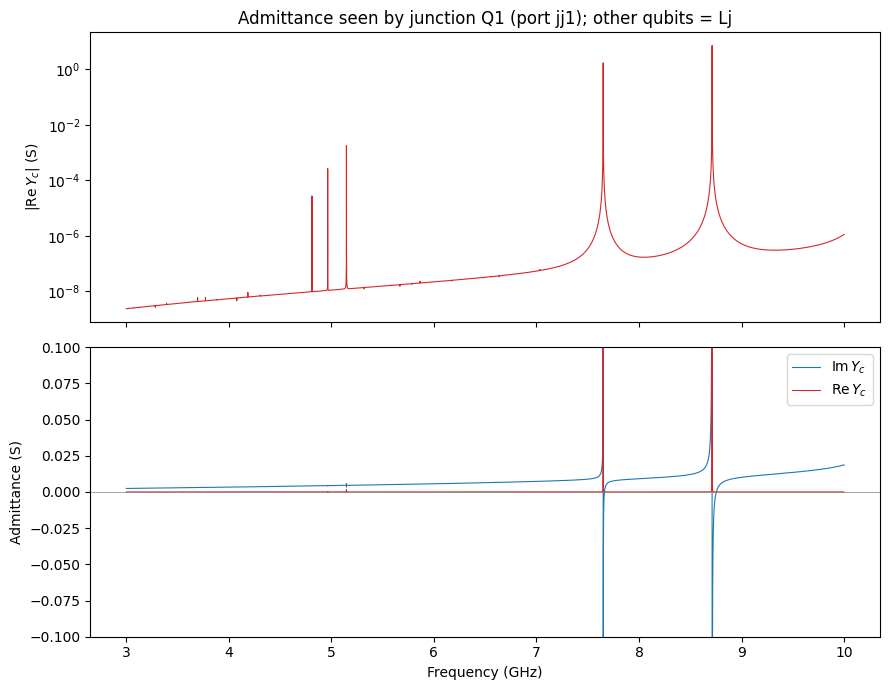

In [ ]:
# Admittance graph: Re(Y) alone, then Re(Y) and Im(Y) together  (reloads from disk; no HFSS needed)
Y1_NPZ = BASE / "data/driven_modal" / f"Y_Q{Q_DRIVE}_single_port.npz"   # so this cell runs without HFSS
d1 = np.load(Y1_NPZ)
f_dm1, Y_dm1 = d1["f"], d1["Y"]
fg = f_dm1 / giga

fig, (ax_re, ax_both) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
ax_re.semilogy(fg, np.abs(Y_dm1.real), color="tab:red", lw=0.8)
ax_re.set_ylabel(r"$|\mathrm{Re}\,Y_c|$ (S)")
ax_re.set_title(f"Admittance seen by junction Q{Q_DRIVE} (port {PORT_DM1}); other qubits = Lj")

ax_both.plot(fg, Y_dm1.imag, color="tab:blue", lw=0.8, label=r"$\mathrm{Im}\,Y_c$")
ax_both.plot(fg, Y_dm1.real, color="tab:red", lw=0.8, label=r"$\mathrm{Re}\,Y_c$")
ax_both.axhline(0, color="0.5", lw=0.5)
ax_both.set_ylim(-0.1, 0.1)
ax_both.set_xlabel("Frequency (GHz)")
ax_both.set_ylabel("Admittance (S)")
ax_both.legend(loc="upper right")
fig.tight_layout()
fig.savefig(BASE / "figures" / f"admittance_Q{Q_DRIVE}_single_port.pdf")
plt.show()

### Black-box quantization of Q_DRIVE (pybbq)
Full single-junction routine: add the junction's linear admittance (`L_J = LJ_NH[Q_DRIVE - 1]`,
`C_J = CJ_BBQ_FF`) → modes at the upward zero crossings of Im(Y_c + Y_J) → per-mode L, C, R, Z, Φ_zpf, Q →
couplings g, participation ratios → χ matrix (anharmonicity, dispersive shifts to the other modes).
The qubit is the mode with the largest Φ_zpf at this junction. Runs from the saved `.npz`.
The other three `Lj` are inside the HFSS solve here, so after changing `LJ_NH` this design must be re-solved (the saved npz records the `Lj_nH` it was solved with; the cell below warns on a mismatch).

The other three qubits are real modes of this circuit, but seen from junction Q_DRIVE they have tiny Φ_zpf and
narrow zero crossings, so pybbq may not resolve them; cross-Kerr between qubits needs EPR or a multi-junction model.

In [ ]:
from pybbq import BBQAnalysis

_saved_lj = np.load(Y1_NPZ)["Lj_nH"]
if not np.allclose(_saved_lj, LJ_NH):
    print(f"[dm1] WARNING: {Y1_NPZ.name} was solved with Lj = {list(_saved_lj)} nH but LJ_NH = {LJ_NH}. "
          f"The other three junctions are baked into that solve: re-solve DM_1port before trusting this BBQ.")

L_J1 = LJ_NH[Q_DRIVE - 1] * 1e-9
C_J1 = CJ_BBQ_FF * 1e-15
bbq1 = BBQAnalysis(Y_dm1, f_dm1, L_J1, C_J1)
bbq1_modes = bbq1.calculate_LCRZPhi()                       # per-mode L, C, R, Z, Phi_zpf, Q
bbq1_info = bbq1.save_BBOX_info(filename=BASE / "data/bbq" / f"bbq_results_Q{Q_DRIVE}_single_port.csv")
print(f"L_J = {L_J1 * 1e9:g} nH, C_J = {C_J1 * 1e15:g} fF, qubit = mode {bbq1.qindex} "
      f"at {bbq1.f_p[bbq1.qindex] / giga:.4f} GHz")
bbq1_info

L_J = 5.35 nH, C_J = 4 fF, qubit = mode 1 at 5.6272 GHz


,Mode frequencies (GHz),Mode couplings (MHz),Mode inductances (nH),Mode capacitances (nF),Mode resistances (Ohms),Mode impedances (Ohm),Dimensionless mode phase fluctuation,Mode Q's
0,5.146945,4.213106,0.000377,2.534959,2.552465e+03,0.012198,0.002437,209247.420865
1,5.627183,0.000000,4.482674,0.000178,5.995858e+07,158.492239,0.277774,378306.116430
2,7.672337,174.947618,0.024058,0.017886,7.221462e+04,1.159770,0.023761,62266.334975
3,8.770587,323.091609,0.030384,0.010838,1.199011e+05,1.674399,0.028551,71608.434501


Mode Frequencies: [5.14694469 5.62718272 7.67233723 8.77058706] GHz


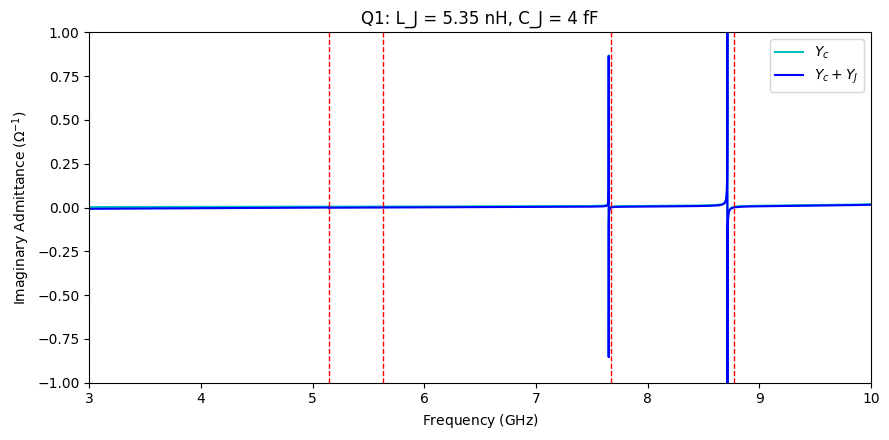

In [ ]:
# Im(Y_c) and Im(Y_c + Y_J); dashed red = modes found (zero crossings)
fig, ax = plt.subplots(figsize=(9, 4.5))
bbq1.plot_admittances(fig=fig, ax=ax, ylim=[-1, 1])
ax.set_title(f"Q{Q_DRIVE}: L_J = {L_J1 * 1e9:g} nH, C_J = {C_J1 * 1e15:g} fF")
fig.tight_layout()
fig.savefig(BASE / "figures" / f"bbq_admittance_Q{Q_DRIVE}_single_port.pdf")
plt.show()

Coupling strengths: [  4.2131058    0.         174.94761788 323.09160862] MHz


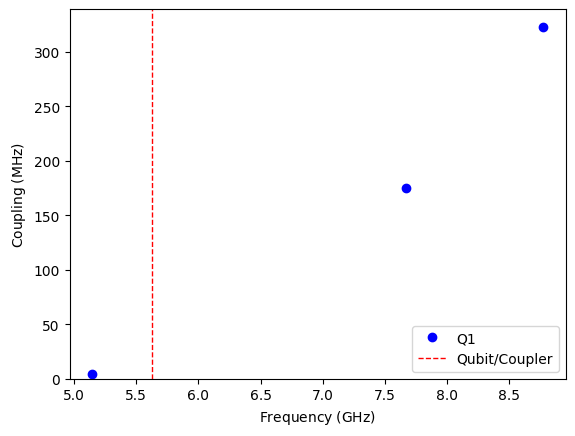

,f (GHz),g (MHz),participation (Phi/Phi_q)^2,Phi_zpf
0,5.146945,4.213106,0.000077,0.002437
1,5.627183,0.000000,1.000000,0.277774
2,7.672337,174.947618,0.007318,0.023761
3,8.770587,323.091609,0.010565,0.028551


In [ ]:
# coupling g of the qubit to every other mode, and participation ratios at this junction
fig, ax = plt.subplots()
bbq1.plot_gs_vs_freq(fig=fig, ax=ax, label=f"Q{Q_DRIVE}")
fig.savefig(BASE / "figures" / f"gs_Q{Q_DRIVE}_single_port.pdf")
plt.show()

pd.DataFrame({"f (GHz)": bbq1.f_p / giga,
              "g (MHz)": bbq1.get_gs(print_results=False) / 1e6,
              "participation (Phi/Phi_q)^2": bbq1.get_participation_ratios(),
              "Phi_zpf": bbq1.Phi_p}).round(6)

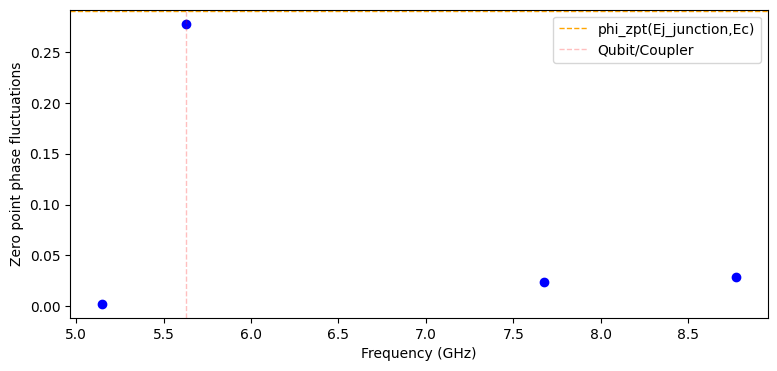

In [ ]:
# zero-point phase fluctuations per mode vs. the bare-transmon value for this L_J and E_C
fig, ax = plt.subplots(figsize=(9, 4))
bbq1.plot_phizpts(fig=fig, ax=ax)
fig.savefig(BASE / "figures" / f"phizpt_Q{Q_DRIVE}_single_port.pdf")
plt.show()

anharmonicity =  -0.09094880129450592 GHz


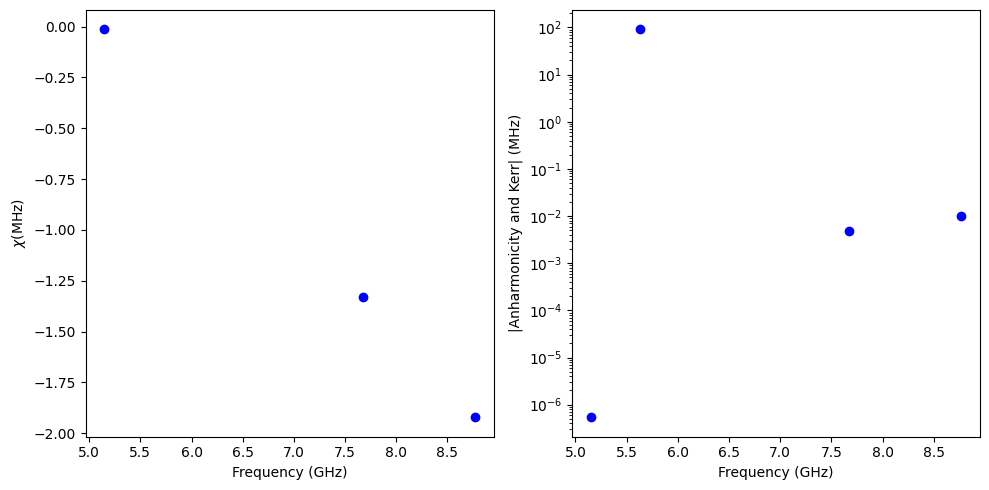

,f (GHz),Q,g to qubit (MHz),chi to qubit (MHz),self-Kerr / anharm. (MHz)
mode 0,5.1469,209247.4209,4.2131,-0.0140,-0.0000
qubit,5.6272,378306.1164,0.0000,-90.9488,-90.9488
mode 2,7.6723,62266.3350,174.9476,-1.3310,-0.0049
mode 3,8.7706,71608.4345,323.0916,-1.9217,-0.0102


In [ ]:
# chi matrix (GHz): diagonal = anharmonicity / self-Kerr, row q = dispersive shifts of the other modes
chi1 = bbq1.Hparams_with_transmon_circuit()
plt.savefig(BASE / "figures" / f"chi_Q{Q_DRIVE}_single_port.pdf")
plt.show()

q = bbq1.qindex
summary1 = pd.DataFrame({
    "f (GHz)": bbq1.f_p / giga,
    "Q": bbq1.Q_p,
    "g to qubit (MHz)": bbq1.get_gs(print_results=False) / 1e6,
    "chi to qubit (MHz)": chi1[q] * 1e3,
    "self-Kerr / anharm. (MHz)": np.diag(chi1) * 1e3,
}, index=[("qubit" if k == q else f"mode {k}") for k in range(len(bbq1.f_p))])
summary1.to_csv(BASE / "data/bbq" / f"bbq_summary_Q{Q_DRIVE}_single_port.csv")
summary1.round(4)

### Cross-check against the 4-port result
If `Y_junctions.npz` from the 4-port section exists, rebuild the same single-junction admittance analytically
(other junctions loaded by their Lj only, C_J = 0 to match the HFSS inductors here) and overlay it. The two curves
should lie on top of each other; differences are mesh/solve differences between the `DM` and single-port designs.

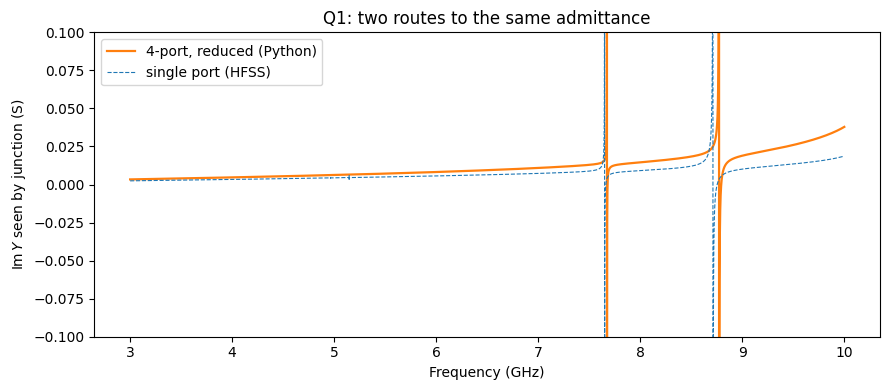

single-port modes (GHz): [5.1469 5.6272 7.6723 8.7706]
4-port reduced modes   : [4.8522 7.6812 8.798 ]


In [ ]:
Y4_NPZ = BASE / "data/driven_modal/Y_junctions.npz"
if Y4_NPZ.exists():
    d4 = np.load(Y4_NPZ)
    f4, Y4 = d4["f"], d4["Y"]
    i = Q_DRIVE - 1
    o = [k for k in range(Y4.shape[1]) if k != i]
    w4 = 2 * np.pi * f4
    Y_load = np.stack([-1j / (w4 * LJ_NH[k] * 1e-9) for k in o], axis=-1)       # Lj only, no C_J
    Y_oo = Y4[:, o][:, :, o] + Y_load[:, :, None] * np.eye(len(o))
    x = np.linalg.solve(Y_oo, Y4[:, o, i][..., None])[..., 0]
    Y_red = Y4[:, i, i] - np.einsum("fk,fk->f", Y4[:, i, o], x)

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(f4 / giga, Y_red.imag, color="tab:orange", lw=1.6, label="4-port, reduced (Python)")
    ax.plot(f_dm1 / giga, Y_dm1.imag, color="tab:blue", lw=0.8, ls="--", label="single port (HFSS)")
    ax.set_ylim(-0.1, 0.1)
    ax.set_xlabel("Frequency (GHz)")
    ax.set_ylabel(r"$\mathrm{Im}\,Y$ seen by junction (S)")
    ax.set_title(f"Q{Q_DRIVE}: two routes to the same admittance")
    ax.legend()
    fig.tight_layout()
    fig.savefig(BASE / "figures" / f"admittance_Q{Q_DRIVE}_1port_vs_4port.pdf")
    plt.show()

    bbq_red = BBQAnalysis(Y_red, f4, L_J1, C_J1)
    bbq_red.calculate_LCRZPhi(return_df=False)
    print("single-port modes (GHz):", np.round(bbq1.f_p / giga, 4))
    print("4-port reduced modes   :", np.round(bbq_red.f_p / giga, 4))
else:
    print("no 4-port Y_junctions.npz yet; run the next section first for this comparison")

# Driven Modal: all four junctions as ports


Same cavity and chips as `EM_Cavity_with_Transmons`, but each junction sheet is a **lumped port** `jj1..jj4`
(`JJ_PORT_Z` = 1 MΩ, as in the SNAIL notebook) instead of an inductor. The readout and drive bores keep their
50 Ω impedance boundaries, so cavity loss through the lines is included.

HFSS returns the **4×4 admittance matrix** Y(ω) between the junction ports. Y does not depend on the port
reference impedance, so the 1 MΩ value does not enter the result.

pybbq is single-port, so for qubit *i* the other three junctions are attached analytically as their linear
elements (L_J,k ∥ C_J):

$$Y_{\text{in},i} = Y_{ii} - Y_{io}\,\big(Y_{oo} + Y_{J,o}\big)^{-1}\,Y_{oi},\qquad o = \{k \neq i\}$$

This is the admittance junction *i* sees with the rest of the circuit in place. All four reductions describe the
same circuit, so they should find the **same mode frequencies**; what differs per junction is Φ_zpf (participation).
Changing `LJ_NH` / `CJ_BBQ_FF` only needs the BBQ cells, not a new HFSS solve.

In [ ]:
use_design("DM", "Modal")
ports = build_cavity()
JUNCTION_PORTS = add_transmons(junction="port")

PyAEDT INFO: Python version 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)].
PyAEDT INFO: PyAEDT version 0.24.1.
PyAEDT INFO: Returning found Desktop session with PID 31852!
PyAEDT INFO: Project coffin_4Q set to active.
PyAEDT INFO: Active Design set to DM
PyAEDT INFO: Aedt Objects correctly read
PyAEDT INFO: Modeler class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Deleted 21 Objects: cavity,substrate_1,substrate_2,substrate_3,substrate_4,pad_1a,pad_1b,jj_1,pad_2a,pad_2b,jj_2,pad_3a,pad_3b,jj_3,pad_4a,pad_4b,jj_4,jj_line_1,jj_line_2,jj_line_3,jj_line_4.
PyAEDT INFO: Step file C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\inventor_files\coffin_4Q_hfss.stp imported
PyAEDT INFO: Materials class has been i

### Setup and sweeps
Adaptive mesh at `DM_FREQ`, then fast sweeps in `chunk`-wide pieces (as in the SNAIL notebook).
SNAIL used 0.1–10 GHz in 50 MHz chunks × 25 000 points (2 kHz step, one Y entry). With 4 ports there are
16 Y entries per point, so the default here is 3–10 GHz in 100 MHz chunks × 10 000 points (10 kHz step,
~110 MB of Y data). Tighten the step around a mode if its Q is not resolved.

In [ ]:
SETUP_DM = "DM"
DM_FREQ  = "4.5GHz"                                            # adaptive meshing frequency (middle of the qubit band)
DM_SWEEP = dict(start=3.0, stop=10.0, chunk=0.1, points=10_000)  # GHz, GHz, GHz, points per chunk

if SETUP_DM in hfss.get_setups():
    hfss.delete_setup(SETUP_DM)                                  # also removes its sweeps
hfss.create_setup(name=SETUP_DM,
                  SolveType="Single",
                  Frequency=DM_FREQ,
                  MaxDeltaS=0.01,
                  MaximumPasses=10,
                  MinimumPasses=3,
                  MinimumConvergedPasses=3,
                  PercentRefinement=30,
                  BasisOrder=-1,
                  DoLambdaRefine=True,
                  DoMaterialLambda=True,
                  SetLambdaTarget=False,
                  Target=0.3333,
                  UseMaxTetIncrease=False,
                  DrivenSolverType="Direct Solver",
                  EnhancedLowFreqAccuracy=False,
                  SaveRadFieldsOnly=False,
                  SaveAnyFields=True)

n_chunks = int(round((DM_SWEEP["stop"] - DM_SWEEP["start"]) / DM_SWEEP["chunk"]))
edges = np.linspace(DM_SWEEP["start"], DM_SWEEP["stop"], n_chunks + 1)
for k, (f0, f1) in enumerate(zip(edges, edges[1:])):
    hfss.create_linear_count_sweep(setup=SETUP_DM, units="GHz",
                                   start_frequency=round(float(f0), 6), stop_frequency=round(float(f1), 6),
                                   num_of_freq_points=DM_SWEEP["points"], name=f"Sweep_{k:03d}",
                                   save_fields=False, sweep_type="Fast")
print(f"[dm] {n_chunks} fast sweeps, {edges[0]:g}-{edges[-1]:g} GHz")

hfss.analyze(setup=SETUP_DM, cores=num_cores)
hfss.save_project()

PyAEDT INFO: Key DrivenSolverType matched internal key 'SolveType' with confidence of 72.
PyAEDT INFO: Key EnhancedLowFreqAccuracy matched internal key 'PortAccuracy' with confidence of 56.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be ignored.
PyAEDT WARNING: Parameter 'ID' is invalid and will be 

True

### Junction Y matrix
Reads `Y(jji,jjj)` from every sweep (only i ≤ j: the network is reciprocal), drops the duplicated
chunk-edge points, and saves `data/driven_modal/Y_junctions.npz` (`f` in Hz, `Y` with shape `(Nf, 4, 4)` in S).

In [ ]:
Y_NPZ = BASE / "data/driven_modal/Y_junctions.npz"


def junction_y_matrix(setup=SETUP_DM):
    # Y(jji,jjj) from every sweep of `setup` -> (f [Hz], Y [Nf, n, n] in S).
    names = [f"jj{i}" for i in range(1, len(QUBIT_X) + 1)]
    n = len(names)
    pairs = [(i, j) for i in range(n) for j in range(i, n)]
    exprs = [f"Y({names[i]},{names[j]})" for i, j in pairs]
    f_all, Y_all = [], []
    for sweep in sorted(hfss.get_sweeps(setup)):
        data = hfss.post.get_solution_data(expressions=exprs, setup_sweep_name=f"{setup} : {sweep}")
        if not data:
            raise RuntimeError(f"no solution data for {setup} : {sweep} (not solved?)")
        f = None
        for (i, j), e in zip(pairs, exprs):
            x, re = data.get_expression_data(e, formula="real", convert_to_SI=True)
            _, im = data.get_expression_data(e, formula="imag", convert_to_SI=True)
            if f is None:
                f = np.asarray(x, dtype=float)
                Y = np.empty((len(f), n, n), dtype=complex)
            Y[:, i, j] = Y[:, j, i] = np.asarray(re) + 1j * np.asarray(im)
        f_all.append(f)
        Y_all.append(Y)
    f, Y = np.concatenate(f_all), np.concatenate(Y_all)
    f, keep = np.unique(f, return_index=True)          # sorted, without the shared chunk edges
    lo, hi = DM_SWEEP["start"] * giga, DM_SWEEP["stop"] * giga
    assert lo * 0.999 <= f[0] and f[-1] <= hi * 1.001, f"frequency axis {f[0]}..{f[-1]} is not in Hz"
    return f, Y[keep]


f_dm, Y_dm = junction_y_matrix()
np.savez(Y_NPZ, f=f_dm, Y=Y_dm, ports=[f"jj{i}" for i in range(1, len(QUBIT_X) + 1)])
print(f"[dm] Y matrix: {len(f_dm)} points, {f_dm[0] / giga:g}-{f_dm[-1] / giga:g} GHz -> {Y_NPZ.name}")

PyAEDT INFO: Parsing C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt.
PyAEDT INFO: File C:\Users\epm114\Documents\GitHub\Cavity work\coffin_4Q\hfss_files\coffin_4Q.aedt correctly loaded. Elapsed time: 0m 1sec
PyAEDT INFO: aedt file load time 0.6101772785186768
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 1sec
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Post class has been initialized! Elapsed time: 0m 0sec
PyAEDT WARNING: No report category provided. Automatically identified Modal Solution Data
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.07240653038024902
Time to initialize solution data:0.2577028274536133
PyAEDT WARNING: No report category provided. Automatically identified Modal Solution Data
PyAEDT INFO: Solution Data Correctly Loaded.
Time to initialize solution data:0.06980085372924805
Time to initialize solution data:0.2711215019226074
PyAE

### Black-box quantization (pybbq)
Runs from the saved `Y_junctions.npz`, so it works without HFSS open. All four junctions are ports in this design, so the Y matrix does not depend on `LJ_NH`: after changing `LJ_NH`, rerun just the transmon-parameter cell and this one (no new solve), as long as the geometry has not changed since the npz was saved. One `BBQAnalysis` per junction, using
the reduced admittance above with `L_J = LJ_NH[i]` (design values, set in the transmon section) and `C_J = CJ_BBQ_FF`.
Each analysis' qubit mode is the one with the largest Φ_zpf at that junction. Cross-Kerr between qubits
is not part of this single-port BBQ; use the EPR section for that.

In [ ]:
from pybbq import BBQAnalysis


def junction_y(f, Lj, Cj=0.0):
    # Linear junction admittance: Lj in parallel with Cj (H, F).
    w = 2 * np.pi * f
    return 1j * w * Cj - 1j / (w * Lj)


def reduced_admittance(f, Y, i, Lj, Cj=0.0):
    # Admittance seen by junction port i with every other junction port k loaded by Lj[k] || Cj:
    # Y_in = Y_ii - Y_io (Y_oo + Y_J,o)^-1 Y_oi
    o = [k for k in range(Y.shape[1]) if k != i]
    Y_load = np.stack([junction_y(f, Lj[k], Cj) for k in o], axis=-1)       # (Nf, n-1)
    Y_oo = Y[:, o][:, :, o] + Y_load[:, :, None] * np.eye(len(o))
    x = np.linalg.solve(Y_oo, Y[:, o, i][..., None])[..., 0]
    return Y[:, i, i] - np.einsum("fk,fk->f", Y[:, i, o], x)


Y_NPZ = BASE / "data/driven_modal/Y_junctions.npz"     # also defined in the extraction cell; here so BBQ runs alone
d = np.load(Y_NPZ)
f_dm, Y_dm = d["f"], d["Y"]
L_J = [l * 1e-9 for l in LJ_NH]
C_J = CJ_BBQ_FF * 1e-15

bbq, summary = {}, {}
for i in range(Y_dm.shape[1]):
    q = f"Q{i + 1}"
    bbq[q] = BBQAnalysis(reduced_admittance(f_dm, Y_dm, i, L_J, C_J), f_dm, L_J[i], C_J)
    bbq[q].calculate_LCRZPhi(return_df=False)
    bbq[q].save_BBOX_info(filename=BASE / "data/bbq" / f"bbq_results_{q}.csv")
    k = bbq[q].qindex
    summary[q] = {"L_J (nH)": LJ_NH[i], "f_q (GHz)": bbq[q].f_p[k] / giga, "Q": bbq[q].Q_p[k],
                  "Phi_zpf": bbq[q].Phi_p[k], "# modes found": len(bbq[q].f_p)}
summary = pd.DataFrame(summary).T
summary.to_csv(BASE / "data/bbq/bbq_summary.csv")

# consistency check: every reduction describes the same circuit, so the mode lists should agree
modes = {q: np.round(b.f_p / giga, 4) for q, b in bbq.items()}
if len({len(m) for m in modes.values()}) > 1:
    print("[bbq] warning: different number of modes per junction:", {q: len(m) for q, m in modes.items()})
summary

[bbq] warning: different number of modes per junction: {'Q1': 4, 'Q2': 5, 'Q3': 5, 'Q4': 4}


,L_J (nH),f_q (GHz),Q,Phi_zpf,# modes found
Q1,5.35,5.599640,379526.335380,0.277519,4.0
Q2,5.93,5.296770,385751.962128,0.287287,5.0
Q3,6.43,5.116042,412775.606499,0.295871,5.0
Q4,7.10,4.958396,477173.864271,0.307908,4.0


Mode Frequencies: [5.29676968 5.59963996 7.68018802 8.779958  ] GHz
Mode Frequencies: [5.1160416  5.29676968 5.59963996 7.68018802 8.77994799] GHz
Mode Frequencies: [4.95839584 5.1160416  5.29676968 7.68018802 8.77994799] GHz
Mode Frequencies: [4.95839584 5.1160316  7.68018802 8.779958  ] GHz


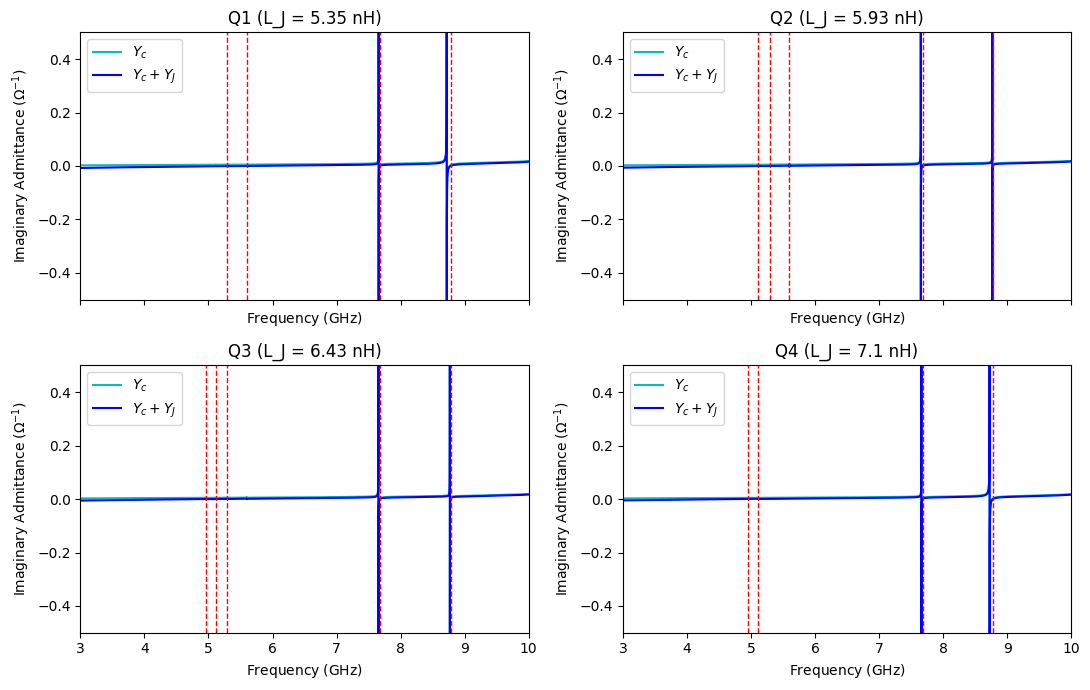

In [ ]:
# Im(Y) seen by each junction; dashed lines = modes (zero crossings of Im(Y_c + Y_J))
fig, axs = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, (q, b) in zip(axs.flat, bbq.items()):
    b.plot_admittances(fig=fig, ax=ax, ylim=[-0.5, 0.5])
    ax.set_title(f"{q} (L_J = {b.L_J * 1e9:g} nH)")
fig.tight_layout()
fig.savefig(BASE / "figures/admittances_junctions.pdf")
plt.show()

Coupling strengths: [  3.66838617   0.         177.73642614 327.97437728] MHz
Coupling strengths: [  2.28191805   0.           4.67345226 207.80841802 143.07141062] MHz
Coupling strengths: [  2.65919919   0.           2.64099507 207.54182432 139.19436575] MHz
Coupling strengths: [  0.           2.02540981 177.14574908 322.088001  ] MHz


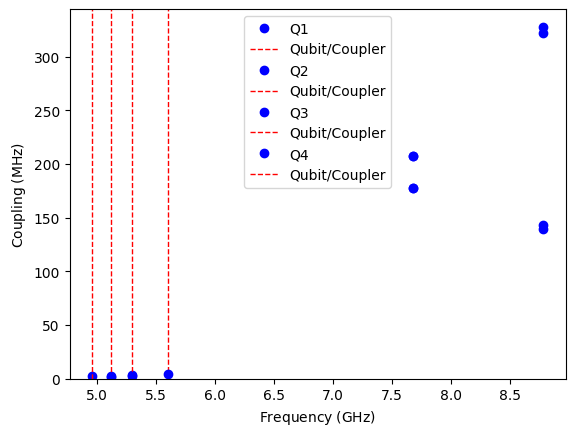

In [ ]:
# coupling of each qubit to the other modes
fig, ax = plt.subplots()
for q, b in bbq.items():
    b.plot_gs_vs_freq(fig=fig, ax=ax, label=q)
fig.savefig(BASE / "figures/gs_junctions.pdf")
plt.show()

# Save & Release HFSS

In [ ]:
hfss.save_project()

PyAEDT INFO: Project coffin_4Q Saved correctly


True

In [ ]:
hfss.release_desktop(close_projects=False, close_desktop=False)   # leaves AEDT open

PyAEDT INFO: Desktop has been released.


True